# Lab Exercise 2 — QA & Chatbot System: Airline Help-Desk Assistant
**Advance NLP (AML23702) · Department of AIML**

**Aim.** Design a question-answering and chatbot system that supports **IR-based factoid answering**, **knowledge-based QA** and **simple dialogue management**, using more than one information source.

**Scenario.** *SkyHelp*, a help-desk assistant for **Skyline Regional Airways** (a fictional domestic airline). It uses two information sources:

| Source | Type | Used for |
|---|---|---|
| 13 policy documents (baggage, check-in, refunds, pets, lounges, …) split into 35 passages | unstructured text | IR-based factoid QA: *"How much does excess baggage cost per kg?"* → **INR 550** |
| Flight database: airports, 22 flights, fares, today's flight status, bookings (SQLite) | structured knowledge base | Knowledge-based QA: *"What time does SR-482 depart?"* → SQL → **14:30** |

On top of these, a **frame-based dialogue manager** handles three multi-turn tasks: flight search, flight status and booking changes.

| Expected outcome (lab sheet) | Where in this notebook |
|---|---|
| Retrieve relevant passages for a question | §2 BM25 passage retrieval (+ TF-IDF baseline, query expansion) |
| Extract factoid answers from text | §3 Answer-type detection and typed answer extraction, with abstention |
| Query structured knowledge sources | §4 Rule-based semantic parser → SQL over the flight database |
| Handle simple conversational interactions | §5 Intent classifier, §6 frame-based dialogue manager |
| Evaluate answer quality | §8 Evaluation on held-out test sets |
| Deliverables: prototype, sample Q-A set, dialogue/frame design, evaluation summary | §7 demo and chat loop, §1 data, §6 frame design, §8 and §9 |

**How to run.** `Kernel → Restart & Run All`. Needs Python 3.10+, spaCy 3.7/3.8 with `en_core_web_sm`, scikit-learn, pandas, matplotlib and python-dateutil. `sqlite3` is part of the Python standard library. Everything runs offline.

In [1]:
# 0. Setup: install anything missing (safe to re-run)
import importlib.util, subprocess, sys

PACKAGES = {"spacy": "spacy>=3.7,<3.9", "sklearn": "scikit-learn", "pandas": "pandas",
            "matplotlib": "matplotlib", "dateutil": "python-dateutil"}
missing = [pip for mod, pip in PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
if importlib.util.find_spec("en_core_web_sm") is None:
    subprocess.check_call([sys.executable, "-m", "spacy", "download", "en_core_web_sm"])
print("environment ready")

environment ready


In [2]:
import json, math, re, sqlite3
from collections import Counter, defaultdict
from dataclasses import dataclass, field
from datetime import date, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spacy
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline, make_union
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from IPython.display import display, Markdown

nlp = spacy.load("en_core_web_sm")
pd.set_option("display.max_colwidth", 90)
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

# The demo "today" is fixed so that relative dates ("tomorrow", "on Friday") and today's
# flight-status table give the same results on every run.
TODAY = date(2026, 10, 20)          # a Tuesday
print("spaCy", spacy.__version__, "| scikit-learn", sklearn.__version__, "| demo date", TODAY.strftime("%a %d %b %Y"))

spaCy 3.8.11 | scikit-learn 1.7.2 | demo date Tue 20 Oct 2026


## 1. Information sources and datasets

### 1.1 Unstructured source — airline policy documents
Thirteen help-centre documents written for this lab in the style of a real airline's customer pages. Each paragraph is one **passage**, the unit that the retriever ranks. The airline, its fees and its rules are fictional; the cities and airports are real.

In [3]:
DOCUMENTS = {
 "D01": ("Checked baggage allowance", [
  "Every Skyline Regional Airways ticket includes a free checked baggage allowance that depends on the fare type. Saver fares include 15 kg of checked baggage, Flex fares include 20 kg and Business fares include 30 kg spread over a maximum of two pieces.",
  "No single checked bag may weigh more than 32 kg, and the sum of its length, width and height must not exceed 158 cm. Infants travelling on a parent's lap are allowed one additional checked bag of up to 10 kg.",
  "Excess baggage bought at the airport costs INR 550 per kg. Passengers who pre-book excess baggage on the website or app at least 4 hours before departure pay INR 450 per kg."]),
 "D02": ("Cabin baggage and batteries", [
  "Saver and Flex passengers may carry one cabin bag weighing up to 7 kg with maximum dimensions of 55 x 35 x 25 cm, plus one personal item such as a laptop bag or handbag weighing up to 3 kg.",
  "Business passengers may carry one cabin bag of up to 10 kg in addition to the personal item. Cabin bags that exceed the limit at the boarding gate are moved to the hold for a fee of INR 1,000.",
  "Power banks and spare lithium batteries must be carried in cabin baggage and are never accepted in the hold. Power banks up to 100 Wh are allowed without approval, while those between 100 Wh and 160 Wh need airline approval."]),
 "D03": ("Check-in and boarding", [
  "Web check-in opens 48 hours before departure and closes 60 minutes before departure. Passengers who check in online can download a mobile boarding pass and go straight to security if they have no checked baggage.",
  "Airport check-in counters open 3 hours before departure and close 45 minutes before departure. Bag drop counters for web-checked passengers close at the same time.",
  "Boarding normally starts 50 minutes before departure and the boarding gate closes 25 minutes before departure. Passengers who reach the gate after it closes cannot board and are treated as a no-show."]),
 "D04": ("Cancellations and refunds", [
  "Saver tickets can be cancelled for a fee of INR 3,500 or the base fare, whichever is lower. Flex tickets carry a cancellation fee of INR 1,000, and Business tickets can be cancelled free of charge up to 24 hours before departure.",
  "Cancellations must be made at least 2 hours before departure. Later cancellations are treated as a no-show, and only the government taxes are refunded.",
  "Refunds are returned to the original form of payment within 7 working days. Refunds for tickets paid in cash at an airport counter are issued as a travel voucher valid for 12 months."]),
 "D05": ("Date changes and name corrections", [
  "The date or time of a Saver booking can be changed for a fee of INR 2,999 plus any fare difference. Flex and Business bookings can be changed without a change fee, but the fare difference still applies.",
  "Changes can be made on the website, in the app or through the contact centre up to 2 hours before the original departure.",
  "Spelling corrections of up to 3 characters in a passenger name are free of charge. A ticket cannot be transferred to a different person."]),
 "D06": ("Delays and flight cancellations", [
  "If a flight is delayed by more than 2 hours, passengers receive a meal voucher at the airport. If the delay is longer than 6 hours, passengers can choose between a free rebooking on the next available flight and a full refund.",
  "When Skyline cancels a flight with less than 2 weeks of notice, passengers are offered an alternative flight or a full refund. For overnight delays caused by the airline, hotel accommodation and airport transfers are provided.",
  "Flight status updates are sent by SMS and e-mail 3 hours before departure. Passengers can also check the live status on the website using the flight number."]),
 "D07": ("Infants and children", [
  "Infants aged between 8 days and 2 years travel on an adult's lap for a fee of INR 1,500 per flight. Each adult may travel with only one lap infant.",
  "Children aged 2 to 12 years must have their own seat and pay the child fare. An unaccompanied minor service is available for children aged 5 to 12 years for a fee of INR 4,000 per flight."]),
 "D08": ("Pets and service animals", [
  "Pets are not allowed in the cabin. Cats and dogs can travel in the cargo hold in an approved carrier for a fee of INR 6,000 per pet, and the combined weight of the pet and carrier must not exceed 32 kg.",
  "Pet bookings must be made at least 48 hours before departure through the contact centre. Trained service dogs accompanying passengers with disabilities travel free of charge in the cabin."]),
 "D09": ("Special assistance and medical travel", [
  "Wheelchair assistance is provided free of charge at all airports Skyline serves. Passengers should request it at least 48 hours before departure.",
  "Expectant mothers can fly without a medical certificate until the end of the 32nd week of pregnancy. Between 32 and 35 weeks a fitness-to-fly certificate issued within 7 days of travel is required, and travel is not permitted after 35 weeks.",
  "Skyline does not provide medical oxygen on board. Passengers who need a stretcher must book it at least 72 hours in advance."]),
 "D10": ("Meals and in-flight services", [
  "Skyline Cafe offers hot meals, snacks and drinks for purchase on all flights. Meals can be pre-booked up to 24 hours before departure at a 10 percent discount.",
  "Flex and Business fares include a complimentary meal. Saver passengers can buy meals on board or pre-book them.",
  "All Airbus A320neo aircraft offer free in-flight entertainment called SkyStream, which passengers stream to their own devices. USB charging ports are available at every seat on the A320neo."]),
 "D11": ("SkyMiles frequent flyer programme", [
  "SkyMiles is the Skyline frequent flyer programme and membership is free. Members earn 8 miles for every INR 100 spent on Saver fares, 12 miles on Flex fares and 20 miles on Business fares.",
  "Members reach Silver tier after earning 15,000 miles in a calendar year and Gold tier after 40,000 miles. Gold members receive priority check-in, an extra 10 kg of checked baggage and lounge access.",
  "Miles can be redeemed for award tickets starting from 5,000 miles. Miles expire if an account has no earning or redemption activity for 36 months."]),
 "D12": ("Airport lounges", [
  "Business passengers and SkyMiles Gold members can use partner lounges at Bengaluru, Delhi and Mumbai airports. The lounges are open from 04:00 to 23:00 every day.",
  "Each eligible passenger may bring one guest for a fee of INR 1,200. Lounge access is available up to 3 hours before the departure of the passenger's flight."]),
 "D13": ("Contact and customer care", [
  "The Skyline contact centre is open 24 hours a day, 7 days a week. Customers can also reach the support team by e-mail at care@skyline-regional.example.",
  "Complaints are acknowledged within 24 hours and resolved within 30 days."]),
}

PASSAGES = pd.DataFrame([{"pid": f"{d}-P{i+1}", "doc": d, "title": t, "text": p}
                         for d, (t, ps) in DOCUMENTS.items() for i, p in enumerate(ps)])
print(len(DOCUMENTS), "documents,", len(PASSAGES), "passages,",
      sum(len(t.split()) for t in PASSAGES.text), "words")
PASSAGES.head(6)

13 documents, 35 passages, 1095 words


,pid,doc,title,text
0,D01-P1,D01,Checked baggage allowance,Every Skyline Regional Airways ticket includes a free checked baggage allowance that d...
1,D01-P2,D01,Checked baggage allowance,"No single checked bag may weigh more than 32 kg, and the sum of its length, width and ..."
2,D01-P3,D01,Checked baggage allowance,Excess baggage bought at the airport costs INR 550 per kg. Passengers who pre-book exc...
3,D02-P1,D02,Cabin baggage and batteries,Saver and Flex passengers may carry one cabin bag weighing up to 7 kg with maximum dim...
4,D02-P2,D02,Cabin baggage and batteries,Business passengers may carry one cabin bag of up to 10 kg in addition to the personal...
5,D02-P3,D02,Cabin baggage and batteries,Power banks and spare lithium batteries must be carried in cabin baggage and are never...


### 1.2 Structured source — flight knowledge base (SQLite)
Five tables: `airports`, `flights` (22 scheduled flights), `fares` (3 fare classes per flight), `flight_status` (status for the fixed demo date) and `bookings`. `make_db()` builds a fresh in-memory copy, so a demo conversation that changes a booking never affects the next one.

In [4]:
AIRPORTS = [  # code, city, airport name, terminal used by Skyline, aliases
 ("BLR", "Bengaluru", "Kempegowda International Airport", "T2", "bangalore"),
 ("DEL", "Delhi", "Indira Gandhi International Airport", "T1", "new delhi"),
 ("BOM", "Mumbai", "Chhatrapati Shivaji Maharaj International Airport", "T2", "bombay"),
 ("MAA", "Chennai", "Chennai International Airport", "T1", "madras"),
 ("HYD", "Hyderabad", "Rajiv Gandhi International Airport", "Main terminal", ""),
 ("COK", "Kochi", "Cochin International Airport", "T1", "cochin"),
 ("CCU", "Kolkata", "Netaji Subhas Chandra Bose International Airport", "Integrated terminal", "calcutta"),
 ("PNQ", "Pune", "Pune International Airport", "Main terminal", ""),
 ("AMD", "Ahmedabad", "Sardar Vallabhbhai Patel International Airport", "T1", ""),
 ("GOX", "Goa", "Manohar International Airport", "Main terminal", "mopa"),
]
FLIGHTS = [  # flight, from, to, departs, arrives, minutes, aircraft, operating days
 ("SR-101", "BLR", "DEL", "06:10", "08:55", 165, "Airbus A320neo", "Daily"),
 ("SR-102", "DEL", "BLR", "09:40", "12:25", 165, "Airbus A320neo", "Daily"),
 ("SR-482", "BLR", "DEL", "14:30", "17:15", 165, "Airbus A320neo", "Daily"),
 ("SR-483", "DEL", "BLR", "18:05", "20:50", 165, "Airbus A320neo", "Daily"),
 ("SR-205", "BLR", "BOM", "07:20", "09:00", 100, "Airbus A321", "Daily"),
 ("SR-206", "BOM", "BLR", "10:00", "11:40", 100, "Airbus A321", "Daily"),
 ("SR-311", "MAA", "COK", "08:15", "09:35", 80, "ATR 72-600", "Mon,Wed,Fri,Sun"),
 ("SR-312", "COK", "MAA", "10:15", "11:35", 80, "ATR 72-600", "Mon,Wed,Fri,Sun"),
 ("SR-415", "BOM", "CCU", "12:10", "14:55", 165, "Airbus A320neo", "Daily"),
 ("SR-416", "CCU", "BOM", "15:45", "18:35", 170, "Airbus A320neo", "Daily"),
 ("SR-520", "HYD", "PNQ", "06:45", "08:05", 80, "ATR 72-600", "Tue,Thu,Sat"),
 ("SR-521", "PNQ", "HYD", "08:45", "10:05", 80, "ATR 72-600", "Tue,Thu,Sat"),
 ("SR-633", "AMD", "MAA", "13:20", "15:50", 150, "Airbus A320neo", "Daily"),
 ("SR-634", "MAA", "AMD", "16:40", "19:10", 150, "Airbus A320neo", "Daily"),
 ("SR-742", "DEL", "GOX", "11:05", "13:40", 155, "Airbus A321", "Fri,Sat,Sun"),
 ("SR-743", "GOX", "DEL", "14:30", "17:05", 155, "Airbus A321", "Fri,Sat,Sun"),
 ("SR-808", "BLR", "HYD", "19:30", "20:40", 70, "ATR 72-600", "Daily"),
 ("SR-809", "HYD", "BLR", "21:15", "22:25", 70, "ATR 72-600", "Daily"),
 ("SR-915", "CCU", "BLR", "07:00", "09:45", 165, "Airbus A320neo", "Daily"),
 ("SR-916", "BLR", "CCU", "20:15", "23:00", 165, "Airbus A320neo", "Daily"),
 ("SR-131", "BLR", "MAA", "09:10", "10:05", 55, "ATR 72-600", "Daily"),
 ("SR-132", "MAA", "BLR", "10:45", "11:40", 55, "ATR 72-600", "Daily"),
]
def _r99(x): return int(x // 100) * 100 + 99
FARES = []
for f, o, d, dep, arr, mins, ac, days in FLIGHTS:
    saver = _r99(1200 + 28 * mins + (int(f[3:]) % 7) * 150)      # deterministic synthetic fares
    FARES += [(f, "Saver", saver), (f, "Flex", _r99(saver * 1.4)), (f, "Business", _r99(saver * 2.9))]
STATUS = [  # flight, date, status, gate, estimated departure  (flights not listed run to schedule)
 ("SR-101", TODAY.isoformat(), "Departed", "11", "06:10"),
 ("SR-482", TODAY.isoformat(), "Delayed", "14", "15:15"),
 ("SR-205", TODAY.isoformat(), "On time", "22", "07:20"),
 ("SR-415", TODAY.isoformat(), "Cancelled", None, None),
 ("SR-808", TODAY.isoformat(), "On time", "9", "19:30"),
 ("SR-633", TODAY.isoformat(), "Delayed", "4", "14:05"),
]
BOOKINGS = [  # PNR, passenger, flight, date, fare class, seat
 ("K7Q2XZ", "A. Rao", "SR-482", "2026-10-24", "Saver", "14C"),
 ("M3P9LD", "N. Iyer", "SR-311", "2026-10-23", "Flex", "3A"),
 ("T5W8HB", "S. Khan", "SR-742", "2026-10-23", "Business", "1D"),
 ("B2R6NC", "P. Das", "SR-205", "2026-10-21", "Saver", "18F"),
]

def make_db():
    con = sqlite3.connect(":memory:")
    con.executescript("""
      CREATE TABLE airports(code TEXT PRIMARY KEY, city TEXT, name TEXT, terminal TEXT, aliases TEXT);
      CREATE TABLE flights(flight_no TEXT PRIMARY KEY, origin TEXT REFERENCES airports(code),
                           destination TEXT REFERENCES airports(code), dep_time TEXT, arr_time TEXT,
                           duration_min INTEGER, aircraft TEXT, days TEXT);
      CREATE TABLE fares(flight_no TEXT, fare_class TEXT, price INTEGER);
      CREATE TABLE flight_status(flight_no TEXT, date TEXT, status TEXT, gate TEXT, est_dep TEXT);
      CREATE TABLE bookings(pnr TEXT PRIMARY KEY, passenger TEXT, flight_no TEXT, date TEXT,
                            fare_class TEXT, seat TEXT);""")
    con.executemany("INSERT INTO airports VALUES (?,?,?,?,?)", AIRPORTS)
    con.executemany("INSERT INTO flights VALUES (?,?,?,?,?,?,?,?)", FLIGHTS)
    con.executemany("INSERT INTO fares VALUES (?,?,?)", FARES)
    con.executemany("INSERT INTO flight_status VALUES (?,?,?,?,?)", STATUS)
    con.executemany("INSERT INTO bookings VALUES (?,?,?,?,?,?)", BOOKINGS)
    return con

DB = make_db()
def fare(flight, cls="Saver"):
    return DB.execute("SELECT price FROM fares WHERE flight_no=? AND fare_class=?", (flight, cls)).fetchone()[0]
for t in ["airports", "flights", "fares", "flight_status", "bookings"]:
    print(f"{t:14s}", DB.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0], "rows")
pd.read_sql("SELECT * FROM flights LIMIT 8", DB)

airports       10 rows
flights        22 rows
fares          66 rows
flight_status  6 rows
bookings       4 rows


,flight_no,origin,destination,dep_time,arr_time,duration_min,aircraft,days
0,SR-101,BLR,DEL,06:10,08:55,165,Airbus A320neo,Daily
1,SR-102,DEL,BLR,09:40,12:25,165,Airbus A320neo,Daily
2,SR-482,BLR,DEL,14:30,17:15,165,Airbus A320neo,Daily
3,SR-483,DEL,BLR,18:05,20:50,165,Airbus A320neo,Daily
4,SR-205,BLR,BOM,07:20,09:00,100,Airbus A321,Daily
5,SR-206,BOM,BLR,10:00,11:40,100,Airbus A321,Daily
6,SR-311,MAA,COK,08:15,09:35,80,ATR 72-600,"Mon,Wed,Fri,Sun"
7,SR-312,COK,MAA,10:15,11:35,80,ATR 72-600,"Mon,Wed,Fri,Sun"


### 1.3 Question–answer sets, intent data and test dialogues
All evaluation data was **written before the system was built** and split into a **development** set (used while writing rules and choosing thresholds) and a **held-out test** set. The test set was scored **once**, after the system was frozen. Test questions are deliberately paraphrased: *luggage* instead of *baggage*, *kilos* instead of *kg*, *Bangalore* and *Madras* instead of *Bengaluru* and *Chennai*, *take off* instead of *depart*. Some questions have no answer in the documents, and for those the correct behaviour is to say so.

In [5]:
# ---- IR-based factoid QA: (question, gold answer or None if unanswerable, gold passage)
FAQ_DEV = [
 ("How much checked baggage is included with a Saver fare?", "15 kg", "D01-P1"),
 ("What is the checked baggage allowance for Business fares?", "30 kg", "D01-P1"),
 ("What is the maximum weight of a single checked bag?", "32 kg", "D01-P2"),
 ("How much does excess baggage cost per kg at the airport?", "INR 550", "D01-P3"),
 ("What is the weight limit for a cabin bag?", "7 kg", "D02-P1"),
 ("When does web check-in open?", "48 hours", "D03-P1"),
 ("When do airport check-in counters close?", "45 minutes", "D03-P2"),
 ("How long before departure does the boarding gate close?", "25 minutes", "D03-P3"),
 ("What is the cancellation fee for a Flex ticket?", "INR 1,000", "D04-P1"),
 ("How long do refunds take?", "7 working days", "D04-P3"),
 ("What is the fee to change the date of a Saver booking?", "INR 2,999", "D05-P1"),
 ("How many characters of a name can be corrected for free?", "3 characters", "D05-P3"),
 ("How much is the infant fee per flight?", "INR 1,500", "D07-P1"),
 ("How much does it cost to send a pet in the hold?", "INR 6,000", "D08-P1"),
 ("How many hours in advance should wheelchair assistance be requested?", "48 hours", "D09-P1"),
 ("After how many weeks of pregnancy is travel not permitted?", "35 weeks", "D09-P2"),
 ("What is the in-flight entertainment service called?", "SkyStream", "D10-P3"),
 ("How many miles do members earn per INR 100 on Business fares?", "20 miles", "D11-P1"),
 ("How many miles are needed to reach Gold tier?", "40,000 miles", "D11-P2"),
 ("What is the guest fee for the lounge?", "INR 1,200", "D12-P2"),
 ("How much does it cost to carry a bicycle?", None, None),
 ("How much is Wi-Fi on board?", None, None),
]
FAQ_TEST = [
 ("How many kilos of checked luggage do Flex tickets allow?", "20 kg", "D01-P1"),
 ("What is the largest combined size allowed for a checked bag?", "158 cm", "D01-P2"),
 ("How much do I pay per kg if I pre-book extra baggage online?", "INR 450", "D01-P3"),
 ("How heavy can my personal item be?", "3 kg", "D02-P1"),
 ("What are the maximum dimensions of a cabin bag?", "55 x 35 x 25 cm", "D02-P1"),
 ("How much cabin baggage can Business passengers carry?", "10 kg", "D02-P2"),
 ("Up to what capacity can a power bank be carried without approval?", "100 Wh", "D02-P3"),
 ("How long before the flight does online check-in close?", "60 minutes", "D03-P1"),
 ("At what point does boarding usually begin?", "50 minutes", "D03-P3"),
 ("How much does it cost to cancel a Business ticket two days before the flight?", "free of charge", "D04-P1"),
 ("How long is a refund voucher valid for cash payments?", "12 months", "D04-P3"),
 ("Up to how many hours before departure can I change my booking?", "2 hours", "D05-P2"),
 ("How long must a flight be delayed before I get a meal voucher?", "2 hours", "D06-P1"),
 ("After how many hours of delay can passengers ask for a full refund?", "6 hours", "D06-P1"),
 ("What is the fee for the unaccompanied minor service?", "INR 4,000", "D07-P2"),
 ("What is the maximum combined weight of a pet and its carrier?", "32 kg", "D08-P1"),
 ("How far in advance do pet bookings have to be made?", "48 hours", "D08-P2"),
 ("How long before travel must a stretcher be booked?", "72 hours", "D09-P3"),
 ("What discount do I get for pre-booking a meal?", "10 percent", "D10-P1"),
 ("Which airports have partner lounges?", "Bengaluru, Delhi and Mumbai", "D12-P1"),
 ("After how long do unused miles expire?", "36 months", "D11-P3"),
 ("What is the minimum number of miles needed for an award ticket?", "5,000 miles", "D11-P3"),
 ("What is the customer care email address?", "care@skyline-regional.example", "D13-P1"),
 ("Within how many days are complaints resolved?", "30 days", "D13-P2"),
 ("How much does Wi-Fi cost on Skyline flights?", None, None),
 ("How many kg of sports equipment can I check in for free?", None, None),
 ("What is the fee for travelling with a musical instrument?", None, None),
 ("How early do I need to arrive for an international flight?", None, None),
]

# ---- Knowledge-based QA: gold = flight numbers expected (set match) and/or strings that must appear
KB_DEV = [
 ("What time does SR-482 depart?", {"contains": ["14:30"]}),
 ("When does SR-101 arrive in Delhi?", {"contains": ["08:55"]}),
 ("Which aircraft operates SR-311?", {"contains": ["ATR 72-600"]}),
 ("Which flights go from Bengaluru to Delhi?", {"flights": ["SR-101", "SR-482"]}),
 ("How long is the flight from Chennai to Kochi?", {"contains": ["1 h 20 min"]}),
 ("What is the cheapest fare from Bengaluru to Mumbai?", {"contains": ["SR-205", "INR {:,}".format(fare("SR-205"))]}),
 ("Which terminal does Skyline use at Delhi?", {"contains": ["T1"]}),
 ("What is the airport code for Goa?", {"contains": ["GOX"]}),
 ("How many flights depart from Bengaluru?", {"contains": ["6"]}),
 ("Where can I fly from Hyderabad?", {"contains": ["Pune", "Bengaluru"]}),
 ("What is the earliest flight from Delhi to Bengaluru?", {"flights": ["SR-102"]}),
 ("On which days does SR-742 operate?", {"contains": ["Fri", "Sat", "Sun"]}),
]
KB_TEST = [
 ("At what time does flight SR 205 take off?", {"contains": ["07:20"]}),
 ("What time does SR-916 land?", {"contains": ["23:00"]}),
 ("What type of plane flies SR-633?", {"contains": ["A320neo"]}),
 ("Show me flights from Bangalore to Kolkata", {"flights": ["SR-916"]}),
 ("How long does it take to fly from Mumbai to Kolkata?", {"contains": ["2 h 45 min"]}),
 ("What's the lowest price from Delhi to Goa?", {"contains": ["SR-742", "INR {:,}".format(fare("SR-742"))]}),
 ("How much is a Business class ticket on SR-482?", {"contains": ["INR {:,}".format(fare("SR-482", "Business"))]}),
 ("Which terminal at Mumbai airport does Skyline use?", {"contains": ["T2"]}),
 ("What is the name of the airport in Chennai?", {"contains": ["Chennai International Airport"]}),
 ("Which city has the airport code COK?", {"contains": ["Kochi"]}),
 ("How many flights leave from Madras?", {"contains": ["3"]}),
 ("What destinations can I reach from Kolkata?", {"contains": ["Mumbai", "Bengaluru"]}),
 ("What is the last flight from Bengaluru to Delhi?", {"flights": ["SR-482"]}),
 ("Does SR-520 fly on Mondays?", {"contains": ["No"]}),
]
print(f"FAQ dev {len(FAQ_DEV)} / test {len(FAQ_TEST)} | KBQA dev {len(KB_DEV)} / test {len(KB_TEST)}")

FAQ dev 22 / test 28 | KBQA dev 12 / test 14


In [6]:
# ---- Intent classification data (8 intents). Training utterances and a separate held-out test set.
INTENT_TRAIN = {
 "faq": ["How much checked baggage can I bring?", "What is the cancellation fee?", "When does web check-in open?",
   "Can I take my dog on the plane?", "How much does excess baggage cost?", "What is the cabin bag limit?",
   "Do you serve meals on board?", "How do I earn SkyMiles?", "What happens if my flight is delayed?",
   "Can pregnant women fly?", "How long do refunds take?", "Is there a fee for infants?",
   "What are the lounge timings?", "Can I carry a power bank?", "How do I request a wheelchair?",
   "When does the boarding gate close?", "Can I correct a spelling mistake in my name?",
   "What is the fee for unaccompanied minors?", "How can I contact customer care?",
   "Do Flex fares include a meal?", "What is the baggage allowance for Business class?",
   "How early do check-in counters open?", "Is there in-flight entertainment?",
   "When do my miles expire?", "What do I get if my flight is cancelled?"],
 "kb_query": ["What time does FLIGHT depart?", "When does FLIGHT arrive?", "Which aircraft operates FLIGHT?",
   "Which flights go from CITY to CITY?", "How long is the flight from CITY to CITY?",
   "What is the cheapest fare from CITY to CITY?", "Which terminal do you use at CITY?",
   "What is the airport code for CITY?", "How many flights leave from CITY?", "Where can I fly from CITY?",
   "What is the earliest flight from CITY to CITY?", "On which days does FLIGHT operate?",
   "What is the arrival time of FLIGHT?", "Which plane is used on FLIGHT?", "Do you fly from CITY to CITY?",
   "What is the departure time of FLIGHT?", "How much is a Flex ticket on FLIGHT?",
   "What is the last flight from CITY to CITY?", "Which airport do you use in CITY?",
   "List the flights between CITY and CITY", "What is the flight duration of FLIGHT?",
   "Which destinations do you serve from CITY?", "What does a Business ticket from CITY to CITY cost?",
   "Which city is airport code CODE?", "Does FLIGHT fly on Sundays?"],
 "search_flights": ["I want to book a flight", "Find me a flight from CITY to CITY", "I need to fly to CITY",
   "Book me a ticket to CITY on DATE", "I'd like to travel from CITY", "Can you search flights for me?",
   "I want to go to CITY DATE", "Help me find a flight", "Are there any seats from CITY to CITY on DATE?",
   "I need a ticket from CITY to CITY", "Looking for a flight to CITY", "I want to fly from CITY to CITY on DATE",
   "Search flights to CITY", "Get me a flight to CITY DATE", "I am planning a trip to CITY",
   "Please book a flight for DATE", "I'd like to book a Business class seat to CITY",
   "Show me available flights on DATE", "I have to travel to CITY next week", "Find a cheap flight to CITY",
   "Can I get a flight from CITY?", "I need to get to CITY by DATE", "I want to buy a ticket",
   "Book a Saver fare from CITY to CITY", "Plan a flight for me"],
 "flight_status": ["What is the status of FLIGHT?", "Is FLIGHT on time?", "Is my flight delayed?",
   "Check flight status", "Has FLIGHT departed?", "Which gate is FLIGHT leaving from?",
   "Is FLIGHT cancelled today?", "Track flight FLIGHT", "When will FLIGHT actually leave?",
   "Can you check if my flight is on schedule?", "Status of FLIGHT please", "Is there a delay on FLIGHT?",
   "Tell me the live status of my flight", "Is FLIGHT running late?", "What gate does FLIGHT board at?",
   "I want to know my flight status", "Is FLIGHT on time DATE?", "Did FLIGHT leave yet?",
   "Flight status for FLIGHT", "Is my flight still on?", "Has my flight been cancelled?",
   "Check whether FLIGHT is delayed", "How late is FLIGHT?", "Give me the status of my flight",
   "Is FLIGHT boarding?"],
 "change_booking": ["I need to change my booking", "Can I move my flight to DATE?", "Reschedule my trip",
   "Change the date of my ticket", "I want to modify my reservation", "Move booking PNR to DATE",
   "Please change my flight date", "I'd like to rebook my flight", "Can I travel on a different day?",
   "Postpone my flight to DATE", "Change booking PNR", "I want to shift my journey to DATE",
   "My PNR is PNR and I want to change the date", "Can you reschedule booking PNR?",
   "I need to fly on a different date", "Modify my booking please", "Change my travel date",
   "I want to bring my flight forward to DATE", "Rebook PNR for DATE", "Update the date on my reservation",
   "I can't travel on that day, please change it", "Switch my flight to DATE", "Amend my booking",
   "Help me change my flight", "I want to alter my trip date"],
 "greet": ["hi", "hello", "hey", "good morning", "good evening", "hi there", "hello SkyHelp", "hey there",
   "namaste", "good afternoon", "hiya", "greetings", "hello, anyone there?", "hi bot", "morning",
   "hey, how are you?", "hello there", "yo", "hi, I need some help", "hello, good day",
   "howdy", "hey SkyHelp", "hi again", "hello friend", "good morning, SkyHelp"],
 "thanks": ["thanks", "thank you", "thanks a lot", "that was helpful", "great, thanks", "thank you so much",
   "cheers", "many thanks", "thanks for your help", "perfect, thank you", "awesome thanks", "thx",
   "much appreciated", "that's great, thanks", "thank you very much", "ok thanks", "nice, thank you",
   "thanks, that helps", "brilliant, thanks", "appreciate it", "ty", "super, thanks", "lovely, thank you",
   "thanks a ton", "wonderful, thanks"],
 "goodbye": ["bye", "goodbye", "see you", "that's all", "bye bye", "see you later", "I'm done", "exit",
   "nothing else", "that is all for now", "good night", "talk to you later", "quit", "ciao",
   "have a nice day", "bye for now", "no more questions", "end chat", "catch you later", "farewell",
   "ok bye", "see ya", "I have to go", "close the chat", "that's everything"],
}
INTENT_TEST = [
 ("Can I bring my cat in the cabin?", "faq"), ("What's the excess luggage charge?", "faq"),
 ("How many kilos can I check in on a Saver ticket?", "faq"), ("Are meals free on Flex fares?", "faq"),
 ("What's the refund policy if I cancel?", "faq"), ("Do kids need their own seat?", "faq"),
 ("Is there a lounge I can use?", "faq"), ("How heavy can my carry-on be?", "faq"),
 ("When should I reach the boarding gate?", "faq"), ("Can I fly when I'm 30 weeks pregnant?", "faq"),
 ("What time does SR-205 take off?", "kb_query"), ("When does SR-916 land?", "kb_query"),
 ("What plane flies SR-633?", "kb_query"), ("Flights from Bangalore to Kolkata?", "kb_query"),
 ("How long is the Mumbai to Kolkata flight?", "kb_query"), ("Lowest fare from Delhi to Goa?", "kb_query"),
 ("Which terminal in Mumbai?", "kb_query"), ("What's the code of Chennai airport?", "kb_query"),
 ("How many flights leave from Madras?", "kb_query"), ("Does SR-520 operate on Mondays?", "kb_query"),
 ("I'd like to fly to Pune on Friday", "search_flights"), ("Can you find me a seat to Goa?", "search_flights"),
 ("Book a flight from Delhi to Bengaluru", "search_flights"), ("I need to travel tomorrow", "search_flights"),
 ("Get me to Kolkata next Monday", "search_flights"), ("I want a ticket to Chennai", "search_flights"),
 ("Help me book a trip to Kochi", "search_flights"), ("I'm looking for flights on 30 October", "search_flights"),
 ("I have to fly out of Hyderabad", "search_flights"), ("Reserve a Flex seat to Mumbai", "search_flights"),
 ("Is SR-415 on time today?", "flight_status"), ("Has SR-101 left?", "flight_status"),
 ("Is my flight running on time?", "flight_status"), ("What's the gate for SR-808?", "flight_status"),
 ("Was SR-415 cancelled?", "flight_status"), ("Can you check a flight status for me?", "flight_status"),
 ("Is there any delay on SR-482?", "flight_status"), ("Live status of SR-633", "flight_status"),
 ("Did my flight leave on schedule?", "flight_status"), ("Is SR-205 boarding now?", "flight_status"),
 ("I'd like to reschedule my trip", "change_booking"), ("Can I change the date on booking K7Q2XZ?", "change_booking"),
 ("Move my flight to Sunday", "change_booking"), ("I want to change my reservation", "change_booking"),
 ("Please postpone my ticket", "change_booking"), ("Shift booking M3P9LD to next week", "change_booking"),
 ("I need to rebook for another day", "change_booking"), ("Change my booking date please", "change_booking"),
 ("Can my trip be moved?", "change_booking"), ("I want to fly a day later than booked", "change_booking"),
 ("hello there", "greet"), ("hey hey", "greet"), ("good morning to you", "greet"), ("hi SkyHelp", "greet"),
 ("hello, is anyone here?", "greet"), ("hey, good evening", "greet"), ("hi, can you help", "greet"),
 ("greetings, bot", "greet"), ("hullo", "greet"), ("heya", "greet"),
 ("thanks so much", "thanks"), ("that's very helpful, thank you", "thanks"), ("ok, thanks!", "thanks"),
 ("thank u", "thanks"), ("great help, cheers", "thanks"), ("thanks mate", "thanks"),
 ("I appreciate your help", "thanks"), ("fantastic, thanks", "thanks"), ("thank you kindly", "thanks"),
 ("many thanks for that", "thanks"),
 ("goodbye then", "goodbye"), ("bye now", "goodbye"), ("see you soon", "goodbye"), ("I'm all done", "goodbye"),
 ("that's all I needed", "goodbye"), ("good night, bot", "goodbye"), ("talk later", "goodbye"),
 ("I'll leave now", "goodbye"), ("nothing more, bye", "goodbye"), ("end the conversation", "goodbye"),
]
OUT_OF_SCOPE = ["What's the weather in Paris?", "Tell me a joke", "Who won the cricket match yesterday?",
                "Can you recommend a good restaurant?", "What is the capital of France?",
                "Play some music"]
print({k: len(v) for k, v in INTENT_TRAIN.items()}, "| test", len(INTENT_TEST), "| out-of-scope", len(OUT_OF_SCOPE))

{'faq': 25, 'kb_query': 25, 'search_flights': 25, 'flight_status': 25, 'change_booking': 25, 'greet': 25, 'thanks': 25, 'goodbye': 25} | test 80 | out-of-scope 6


In [7]:
# ---- Scripted dialogues: user turns + what a successful conversation must end with
DIALOGUES_DEV = [
 {"name": "basic search", "turns": ["Hi", "I want to book a flight", "from Bengaluru", "to Delhi", "tomorrow"],
  "expect": {"frame": "search_flights", "slots": {"origin": "BLR", "destination": "DEL", "date": "2026-10-21"},
             "outcome": "results", "contains": ["SR-101", "SR-482"]}},
 {"name": "status in one turn", "turns": ["What's the status of SR-482?"],
  "expect": {"frame": "flight_status", "slots": {"flight_no": "SR-482"}, "outcome": "status", "contains": ["Delayed", "15:15"]}},
 {"name": "change booking", "turns": ["I need to change my booking", "K7Q2XZ", "move it to 25 October", "yes"],
  "expect": {"frame": "change_booking", "slots": {"pnr": "K7Q2XZ", "new_date": "2026-10-25"}, "outcome": "changed",
             "db": {"K7Q2XZ": "2026-10-25"}, "contains": ["2,999"]}},
 {"name": "over-informative user", "turns": ["Find me a flight from Chennai to Kochi on Friday"],
  "expect": {"frame": "search_flights", "slots": {"origin": "MAA", "destination": "COK", "date": "2026-10-23"},
             "outcome": "results", "contains": ["SR-311"]}},
 {"name": "FAQ interruption", "turns": ["I want to fly to Mumbai", "How much cabin baggage can I take?", "from Bengaluru", "next Monday"],
  "expect": {"frame": "search_flights", "slots": {"origin": "BLR", "destination": "BOM", "date": "2026-10-26"},
             "outcome": "results", "contains": ["SR-205"]}},
]
DIALOGUES_TEST = [
 {"name": "greeting, alias, relative date", "turns": ["hello there", "can you help me find a flight to Hyderabad", "Bangalore", "day after tomorrow", "thanks"],
  "expect": {"frame": "search_flights", "slots": {"origin": "BLR", "destination": "HYD", "date": "2026-10-22"},
             "outcome": "results", "contains": ["SR-808"]}},
 {"name": "status - cancelled flight", "turns": ["Is flight SR-415 on time today?"],
  "expect": {"frame": "flight_status", "slots": {"flight_no": "SR-415"}, "outcome": "status", "contains": ["Cancelled"]}},
 {"name": "reschedule, Flex fare", "turns": ["I'd like to reschedule my trip", "my PNR is M3P9LD", "Sunday", "yes please"],
  "expect": {"frame": "change_booking", "slots": {"pnr": "M3P9LD", "new_date": "2026-10-25"}, "outcome": "changed",
             "db": {"M3P9LD": "2026-10-25"}}},
 {"name": "user corrects origin", "turns": ["Book a flight from Delhi to Goa", "Saturday", "sorry, I meant from Mumbai"],
  "expect": {"frame": "search_flights", "slots": {"origin": "BOM", "destination": "GOX", "date": "2026-10-24"},
             "outcome": "no_flights"}},
 {"name": "status - slot request", "turns": ["Can you check a flight status for me?", "SR-808"],
  "expect": {"frame": "flight_status", "slots": {"flight_no": "SR-808"}, "outcome": "status", "contains": ["On time"]}},
 {"name": "change to non-operating day", "turns": ["change booking T5W8HB", "move it to Monday", "then Saturday", "yes"],
  "expect": {"frame": "change_booking", "slots": {"pnr": "T5W8HB", "new_date": "2026-10-24"}, "outcome": "changed",
             "db": {"T5W8HB": "2026-10-24"}}},
 {"name": "KB question mid-task", "turns": ["I want to travel from Ahmedabad to Chennai", "What time does SR-633 leave?", "on 30 October"],
  "expect": {"frame": "search_flights", "slots": {"origin": "AMD", "destination": "MAA", "date": "2026-10-30"},
             "outcome": "results", "contains": ["SR-633"]}},
 {"name": "user declines change", "turns": ["I want to change my reservation B2R6NC to 28 October", "no"],
  "expect": {"frame": "change_booking", "slots": {"pnr": "B2R6NC", "new_date": "2026-10-28"}, "outcome": "not_changed",
             "db": {"B2R6NC": "2026-10-21"}}},
]
print(len(DIALOGUES_DEV), "dev dialogues,", len(DIALOGUES_TEST), "test dialogues")

5 dev dialogues, 8 test dialogues


## 2. IR-based QA, step 1: question processing and passage retrieval

**Text normalisation.** spaCy lemmatises passages and questions. Stop words and punctuation are removed and numbers are kept, so *"cancelled"* and *"cancellation"* end up as close as the lemmatiser allows, and *"INR 100"* stays searchable.

**Query expansion.** Users do not use the same words as the policy writers: *luggage* vs *baggage*, *kilos* vs *kg*, *cost* vs *fee*. A small hand-written synonym table adds the document vocabulary to the query. It was written once, from general airline vocabulary, before any test question was scored.

**Ranking.** Three retrievers are compared:
* **TF-IDF + cosine similarity** (scikit-learn), the classic vector-space baseline.
* **Okapi BM25** (implemented below, k1 = 1.5, b = 0.75). It adds term-frequency saturation and passage-length normalisation.
* **BM25 + query expansion**, the configuration the chatbot uses.

In [8]:
STOP = nlp.Defaults.stop_words | {"skyline", "regional", "airways"}

def analyze(text):
    """Lower-cased lemmas of content words and numbers (for retrieval)."""
    return [t.lemma_.lower() for t in nlp(text)
            if (t.is_alpha or t.like_num) and t.lemma_.lower() not in STOP and len(t.text) > 1]

SYNONYMS = {  # user word -> words the policy documents use
    "luggage": ["baggage"], "suitcase": ["bag", "baggage"], "carry": ["cabin"], "kilo": ["kg"],
    "kilogram": ["kg"], "cost": ["fee"], "price": ["fee"], "charge": ["fee"], "pay": ["fee"],
    "kid": ["child"], "baby": ["infant"], "dog": ["pet"], "cat": ["pet"], "online": ["web"],
    "begin": ["start"], "reservation": ["booking"], "rebook": ["change"], "reschedule": ["change"],
    "plane": ["aircraft"], "pregnant": ["pregnancy"], "lounge": ["lounge"], "food": ["meal"],
    "late": ["delay"], "email": ["mail"], "weight": ["weigh"], "heavy": ["weigh"], "limit": ["maximum"],
}
WH_PHRASES = re.compile(r"\b(how (long|much|many|far|early|soon|heavy|old)|what time|at what point|up to|within how)\b", re.I)
def question_terms(question):
    """Content terms of a question, without the question phrase ('how long', 'how much' ...)."""
    return analyze(WH_PHRASES.sub(" ", question))

def expand(tokens):
    return tokens + [s for t in tokens for s in SYNONYMS.get(t, []) if s not in tokens]

PASSAGE_TOKENS = [analyze(t) for t in PASSAGES.text]

class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.docs, self.k1, self.b = docs, k1, b
        self.N = len(docs)
        self.avgdl = sum(map(len, docs)) / self.N
        self.tf = [Counter(d) for d in docs]
        df = Counter(t for d in docs for t in set(d))
        self.idf = {t: math.log(1 + (self.N - n + 0.5) / (n + 0.5)) for t, n in df.items()}
    def scores(self, query):
        out = np.zeros(self.N)
        for i, (tf, d) in enumerate(zip(self.tf, self.docs)):
            for t in query:
                if t in tf:
                    f = tf[t]
                    out[i] += self.idf[t] * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * len(d) / self.avgdl))
        return out

bm25 = BM25(PASSAGE_TOKENS)
tfidf = TfidfVectorizer(analyzer=lambda x: x).fit(PASSAGE_TOKENS)
TFIDF_MATRIX = tfidf.transform(PASSAGE_TOKENS)

def retrieve(question, method="bm25+exp", k=3):
    q = question_terms(question)
    if method == "tfidf":
        s = (TFIDF_MATRIX @ tfidf.transform([q]).T).toarray().ravel()
    else:
        s = bm25.scores(expand(q) if method == "bm25+exp" else q)
    order = np.argsort(-s, kind="stable")[:k]
    return [(PASSAGES.pid[i], float(s[i])) for i in order]

q = "How many kilos of luggage can I check in?"
print("query tokens:", question_terms(q), "-> expanded:", expand(question_terms(q)))
pd.DataFrame([{"rank": r + 1, "pid": pid, "score": round(s, 2), "passage": PASSAGES.set_index("pid").text[pid][:95] + "..."}
              for r, (pid, s) in enumerate(retrieve(q, k=3))])

query tokens: ['kilo', 'luggage', 'check'] -> expanded: ['kilo', 'luggage', 'check', 'kg', 'baggage']


,rank,pid,score,passage
0,1,D01-P1,6.48,Every Skyline Regional Airways ticket includes a free checked baggage allowance that d...
1,2,D11-P2,5.04,"Members reach Silver tier after earning 15,000 miles in a calendar year and Gold tier ..."
2,3,D01-P3,4.63,Excess baggage bought at the airport costs INR 550 per kg. Passengers who pre-book exc...


## 3. IR-based QA, step 2: answer-type detection and factoid answer extraction

Retrieving a passage is not yet an answer. The extractor follows the classic **question-processing → passage retrieval → answer extraction** design of IR-based factoid QA:

1. **Answer-type detection.** Rules on the question's wording give the expected answer type: `MONEY`, `WEIGHT`, `DURATION`, `TIME`, `PERCENT`, `DIMENSION`, `QUANTITY`, `COUNT(<unit>)`, `NAME`, `CONTACT` or `LOCATION_LIST`. For example, *"how much … cost"* → MONEY, *"how heavy"* → WEIGHT, *"how many miles"* → COUNT(mile), *"which airports"* → LOCATION_LIST.
2. **Candidate generation.** Inside the sentences of the top-3 passages, typed patterns (*INR 1,500*, *7 kg*, *48 hours*, *55 x 35 x 25 cm*), CamelCase product names and spaCy GPE entities produce answer candidates.
3. **Candidate ranking.** Each candidate's score is the sentence score (normalised BM25 score of its passage + IDF-weighted keyword coverage of the sentence) plus a **proximity bonus**: the closer the candidate is to the question's keywords, the higher it scores. This is how *"Business"* selects *20 miles* from *"8 miles … Saver, 12 miles … Flex and 20 miles on Business"*.
4. **Abstention.** If the best sentence covers too little of the question (IDF-weighted coverage below a threshold chosen on the development set), or no candidate of the right type exists, the system answers *"I could not find that in our policy documents"* instead of guessing.

In [9]:
def answer_type(question):
    q = question.lower()
    m = re.search(r"\bhow many (\w+)", q)
    unit = nlp(m.group(1))[0].lemma_.lower() if m else None
    if re.search(r"\bcalled\b|\bname of\b|\bnamed\b", q):                          return ("NAME", None)
    if re.search(r"e-?mail|contact address|phone", q):                              return ("CONTACT", None)
    if re.search(r"\bwhich (airports|cities)\b|\bwhere\b", q):                       return ("LOCATION_LIST", None)
    if re.search(r"percent|discount|%", q):                                          return ("PERCENT", None)
    if unit in {"kg", "kilo", "kilogram"}:                                           return ("WEIGHT", None)
    if unit in {"minute", "hour", "day", "week", "month", "year"}:                   return ("DURATION", unit)
    if unit:                                                                         return ("COUNT", unit)
    if re.search(r"\b(cost|fee|price|charge|pay|paid|fare to)\b", q):                return ("MONEY", None)
    if re.search(r"\b(dimension|size)s?\b", q):                                       return ("DIMENSION", None)
    if re.search(r"\b(capacity|wh|watts?)\b", q):                                         return ("QUANTITY", None)
    if re.search(r"\b(heavy|weigh|weight|kg|kilo|baggage|luggage|allowance)", q):    return ("WEIGHT", None)
    if re.search(r"\bwhat time\b", q):                                               return ("TIME", None)
    if re.search(r"\b(how long|how far in advance|how early|how soon|when|at what point|until|after how|within how)\b", q):
        return ("DURATION", None)
    return ("OTHER", None)

PATTERNS = {
    "MONEY": r"\bINR\s?\d{1,3}(?:,\d{3})+|\bINR\s?\d+",
    "WEIGHT": r"\b\d+(?:\.\d+)?\s?kg\b",
    "DURATION": r"\b\d+\s(?:working\s)?(?:minutes?|hours?|days?|weeks?|months?|years?)\b",
    "TIME": r"\b\d{2}:\d{2}\b",
    "PERCENT": r"\b\d+\s?(?:percent|%)",
    "DIMENSION": r"\b\d+\s?x\s?\d+\s?x\s?\d+\s?cm\b|\b\d+\s?cm\b",
    "QUANTITY": r"\b\d+\s?Wh\b",
    "NAME": r"\b[A-Z][a-z]+[A-Z][a-z]+\w*\b",
    "CONTACT": r"\b[\w.+-]+@[\w-]+\.[\w.-]+\w\b",
}

def candidates(sent, atype, unit):
    """Typed answer candidates inside one spaCy sentence span: list of (text, start_char, end_char)."""
    text, base = sent.text, sent.start_char
    if atype == "LOCATION_LIST":
        gpes = [e for e in sent.ents if e.label_ == "GPE"]
        if not gpes:
            return []
        names = [e.text for e in gpes]
        joined = names[0] if len(names) == 1 else ", ".join(names[:-1]) + " and " + names[-1]
        return [(joined, gpes[0].start_char, gpes[-1].end_char)]
    if atype == "COUNT":
        return [(m.group(0), base + m.start(), base + m.end())
                for m in re.finditer(r"\b(?:\d{1,3}(?:,\d{3})+|\d+)\s+(\w+)", text)
                if m.group(1).lower().rstrip("s") == unit.rstrip("s")]
    pat = PATTERNS.get(atype)
    if pat is None:
        return []
    out = [(m.group(0), base + m.start(), base + m.end()) for m in re.finditer(pat, text)]
    if atype == "DURATION" and unit:
        out = [c for c in out if re.search(unit, c[0])]
    return out

PASSAGE_DOCS = {pid: nlp(t) for pid, t in zip(PASSAGES.pid, PASSAGES.text)}

# Attribute words that distinguish several values listed in one sentence
# ("Saver ... 15 kg, Flex ... 20 kg and Business ... 30 kg"; "opens 48 hours ... closes 60 minutes").
CONTRAST_SETS = [{"saver", "flex", "business"}, {"silver", "gold"}, {"open", "close", "start"}]

def contrast_bonus(sent, span, cand_spans, q_terms):
    """+1 if the attribute word governing this candidate is the one the question asks about, -1 if it is
    a different member of the same set. Whether attributes precede or follow their values is decided per
    sentence from which comes first (attribute-first: 'Flex fares include 20 kg'; value-first: '12 miles on Flex')."""
    bonus = 0.0
    for cset in CONTRAST_SETS:
        asked = cset & set(q_terms)
        members = [t for t in sent if t.lemma_.lower() in cset]
        if not asked or len({t.lemma_.lower() for t in members}) < 2:
            continue
        attribute_first = members[0].i < min(c.start for c in cand_spans)
        side = [t for t in members if (t.i < span.start if attribute_first else t.i >= span.end)]
        if not side:
            continue
        gov = max(side, key=lambda t: t.i) if attribute_first else min(side, key=lambda t: t.i)
        bonus += 1.0 if gov.lemma_.lower() in asked else -1.0
    return bonus
IDF = defaultdict(lambda: IDF_OOV, bm25.idf)
IDF_OOV = max(bm25.idf.values())     # words never seen in the documents count as maximally informative

def qa_answer(question, method="bm25+exp", k=3, tau=0.45, extract=True):
    """IR-based factoid QA. Returns a dict with the answer (or None = abstain) and its evidence."""
    q_orig = question_terms(question)
    q_terms = expand(q_orig)
    atype, unit = answer_type(question)
    hits = retrieve(question, method, k)
    top = max(hits[0][1], 1e-9)
    best, best_sent = None, None
    for pid, pscore in hits:
        doc = PASSAGE_DOCS[pid]
        sents = list(doc.sents)
        for si, sent in enumerate(sents):
            lemmas = [t.lemma_.lower() for t in sent]
            present = {t for t in set(q_terms) if t in lemmas}
            # coverage looks at the sentence plus the one before it, so "Passengers should request it ..."
            # still gets credit for "wheelchair" mentioned in the previous sentence
            window = set(lemmas) | ({t.lemma_.lower() for t in sents[si - 1]} if si else set())
            matched = [t for t in set(q_orig) if t in window or any(x in window for x in SYNONYMS.get(t, []))]
            coverage = sum(IDF[t] for t in matched) / max(1e-9, sum(IDF[t] for t in set(q_orig)))
            s_score = 0.5 * pscore / top + coverage
            if best_sent is None or s_score > best_sent["score"]:
                best_sent = {"score": s_score, "coverage": coverage, "sentence": sent.text, "pid": pid}
            if not extract:
                continue
            cands = [(text, a, b) for text, a, b in candidates(sent, atype, unit)
                     if text.lower() not in question.lower()]   # never answer with what the user already said
            cand_spans = [doc.char_span(a, b, alignment_mode="expand") for _, a, b in cands]
            for (text, a, b), span in zip(cands, cand_spans):
                prox = 0.0
                for t in present:
                    dists = [min(abs(tok.i - span.start), abs(tok.i - span.end + 1))
                             for tok in sent if tok.lemma_.lower() == t]
                    prox += IDF[t] / (1 + min(dists))
                score = s_score + 0.15 * prox + contrast_bonus(sent, span, cand_spans, q_terms)
                if best is None or score > best["score"]:
                    best = {"answer": text, "score": score, "coverage": coverage, "sentence": sent.text, "pid": pid}
    result = {"question": question, "answer_type": atype + (f"({unit})" if unit else ""), "retrieved": [h[0] for h in hits]}
    chosen = best if (extract and best) else best_sent
    if chosen is None or chosen["coverage"] < tau or (extract and best is None and atype != "OTHER"):
        result.update({"answer": None, "sentence": best_sent["sentence"], "pid": best_sent["pid"],
                       "coverage": round(best_sent["coverage"], 2)})
        return result
    result.update({"answer": chosen.get("answer", chosen["sentence"]) if extract else chosen["sentence"],
                   "sentence": chosen["sentence"], "pid": chosen["pid"], "coverage": round(chosen["coverage"], 2)})
    return result

for q in ["How many miles do members earn per INR 100 on Business fares?", "When does web check-in open?",
          "Which airports have partner lounges?", "How much is Wi-Fi on board?"]:
    r = qa_answer(q)
    print(f"Q: {q}\n   type={r['answer_type']:<14} answer={r['answer']!r:<30} evidence [{r['pid']}] {r['sentence'][:80]}...")

Q: How many miles do members earn per INR 100 on Business fares?
   type=COUNT(mile)    answer='20 miles'                     evidence [D11-P1] Members earn 8 miles for every INR 100 spent on Saver fares, 12 miles on Flex fa...
Q: When does web check-in open?
   type=DURATION       answer='48 hours'                     evidence [D03-P1] Web check-in opens 48 hours before departure and closes 60 minutes before depart...
Q: Which airports have partner lounges?
   type=LOCATION_LIST  answer='Bengaluru, Delhi and Mumbai'  evidence [D12-P1] Business passengers and SkyMiles Gold members can use partner lounges at Bengalu...
Q: How much is Wi-Fi on board?
   type=OTHER          answer=None                           evidence [D09-P3] Skyline does not provide medical oxygen on board....


## 4. Knowledge-based QA: semantic parsing to SQL

Questions about schedules, fares and airports are answered from the database, not from text. The parser turns a question into a **logical form** (relation + arguments) and then into a parameterised SQL query. This is the classic semantic-parsing approach to knowledge-based QA.

1. **Entity linking.** A gazetteer built *from the database itself* finds flight numbers (`SR-482`, `SR 482`, `sr482`), cities and their aliases (*Bangalore → Bengaluru*, *Madras → Chennai*, *Bombay → Mumbai*), IATA codes, fare classes and weekdays.
2. **Role labelling.** `from X` → origin, `to X` → destination, otherwise the order of mention.
3. **Relation detection.** Ordered keyword templates select one of 17 relations (`dep_time`, `arr_time`, `aircraft`, `duration`, `days`, `operates_on`, `flight_fare`, `route_flights`, `cheapest`, `earliest`, `latest`, `count_from`, `destinations`, `terminal`, `airport_code`, `airport_name`, `code_to_city`).
4. **SQL execution and answer generation.** The query runs against SQLite and a template turns the rows into a sentence. Every answer comes with the SQL that produced it, which makes the system easy to inspect and explain.

In [10]:
CITY_BY_KEY = {}
for code, city, name, term, aliases in AIRPORTS:
    for key in [city.lower(), code.lower()] + [a for a in aliases.split(",") if a]:
        CITY_BY_KEY[key.strip()] = code
CITY_NAME = {a[0]: a[1] for a in AIRPORTS}
WEEKDAYS = {"monday": "Mon", "tuesday": "Tue", "wednesday": "Wed", "thursday": "Thu", "friday": "Fri",
            "saturday": "Sat", "sunday": "Sun"}
FLIGHT_RE = re.compile(r"\bsr[\s-]?(\d{3})\b", re.I)

def find_cities(text):
    """[(code, role, position)] for every city / alias / IATA code mentioned in the text."""
    low = text.lower()
    found = []
    for key, code in sorted(CITY_BY_KEY.items(), key=lambda kv: -len(kv[0])):
        is_code = len(key) == 3 and key.upper() in CITY_NAME
        pattern = r"\b" + re.escape(key.upper() if is_code else key) + r"\b"
        for m in re.finditer(pattern, text if is_code else low):
            if any(m.start() < e and s < m.end() for _, _, s, e in found):
                continue
            before = low[max(0, m.start() - 6):m.start()]
            role = "origin" if re.search(r"\bfrom\s+$", before) else "destination" if re.search(r"\b(to|for)\s+$", before) else None
            found.append((code, role, m.start(), m.end()))
    found.sort(key=lambda f: f[2])
    return [(c, r, s) for c, r, s, _ in found]

def link_entities(question):
    flights = [f"SR-{m.group(1)}" for m in FLIGHT_RE.finditer(question)]
    cities = find_cities(question)
    origin = next((c for c, r, _ in cities if r == "origin"), None)
    dest = next((c for c, r, _ in cities if r == "destination"), None)
    rest = [c for c, r, _ in cities if r is None]
    if origin is None and rest and (dest is not None or len(rest) > 1):
        origin = rest.pop(0)
    if dest is None and rest and origin is not None:
        dest = rest.pop(0)
    single = cities[0][0] if len(cities) == 1 else None
    cls = next((c for c in ["Business", "Flex", "Saver"] if c.lower() in question.lower()), None)
    day = next((v for k, v in WEEKDAYS.items() if re.search(rf"\b{k}s?\b", question.lower())), None)
    code_q = [w for w in re.findall(r"\b[A-Z]{3}\b", question) if w in CITY_NAME]
    return {"flight": flights[0] if flights else None, "origin": origin, "destination": dest,
            "city": single, "fare_class": cls, "weekday": day, "code": code_q[0] if code_q else None}

def hm(mins):
    return f"{mins // 60} h {mins % 60:02d} min" if mins % 60 else f"{mins // 60} h"

def has(q, *words):
    return any(re.search(rf"\b{w}", q) for w in words)

def parse_kb(question):
    """Question -> (relation, sql, params). Returns None if no template applies."""
    q, e = question.lower(), link_entities(question)
    f, o, d, city, cls = e["flight"], e["origin"], e["destination"], e["city"], e["fare_class"] or "Saver"
    if f:
        if has(q, "aircraft", "plane", "type", "equipment"):
            return "aircraft", "SELECT aircraft FROM flights WHERE flight_no=?", (f,)
        if e["weekday"] and has(q, "fly", "operate", "run", "go"):
            return "operates_on", "SELECT days FROM flights WHERE flight_no=?", (f,)
        if has(q, "which days", "what days", "days", "operate", "schedule"):
            return "days", "SELECT days FROM flights WHERE flight_no=?", (f,)
        if has(q, "arriv", "land", "reach", "get in"):
            return "arr_time", "SELECT arr_time, destination FROM flights WHERE flight_no=?", (f,)
        if has(q, "depart", "leave", "take off", "takes off", "departure", "what time", "when"):
            return "dep_time", "SELECT dep_time, origin FROM flights WHERE flight_no=?", (f,)
        if has(q, "fare", "price", "cost", "ticket", "how much"):
            return "flight_fare", "SELECT price, fare_class FROM fares WHERE flight_no=? AND fare_class=?", (f, cls)
        if has(q, "how long", "duration"):
            return "duration", "SELECT duration_min FROM flights WHERE flight_no=?", (f,)
    if o and d:
        route = "FROM flights WHERE origin=? AND destination=?"
        if has(q, "cheap", "lowest", "least expensive", "price", "fare", "cost", "how much"):
            return "cheapest", ("SELECT f.flight_no, p.price, p.fare_class FROM flights f JOIN fares p USING(flight_no) "
                                "WHERE f.origin=? AND f.destination=? AND p.fare_class=? ORDER BY p.price LIMIT 1"), (o, d, cls)
        if has(q, "earliest", "first"):
            return "earliest", f"SELECT flight_no, dep_time {route} ORDER BY dep_time LIMIT 1", (o, d)
        if has(q, "last", "latest"):
            return "latest", f"SELECT flight_no, dep_time {route} ORDER BY dep_time DESC LIMIT 1", (o, d)
        if has(q, "how long", "duration", "take to fly"):
            return "duration", f"SELECT MIN(duration_min) {route}", (o, d)
        return "route_flights", f"SELECT flight_no, dep_time, arr_time, days {route} ORDER BY dep_time", (o, d)
    if e["code"] and has(q, "city", "which city", "where is"):
        return "code_to_city", "SELECT city, name FROM airports WHERE code=?", (e["code"],)
    c = city or o or d
    if c:
        if has(q, "how many flights"):
            return "count_from", "SELECT COUNT(*) FROM flights WHERE origin=?", (c,)
        if has(q, "terminal"):
            return "terminal", "SELECT terminal, name FROM airports WHERE code=?", (c,)
        if has(q, "code"):
            return "airport_code", "SELECT code FROM airports WHERE code=?", (c,)
        if has(q, "name of the airport", "airport name", "which airport", "what airport", "name"):
            return "airport_name", "SELECT name FROM airports WHERE code=?", (c,)
        if has(q, "where can", "destination", "fly from", "fly to from", "reach from", "can i reach", "where do you fly"):
            return "destinations", ("SELECT DISTINCT a.city FROM flights f JOIN airports a ON a.code=f.destination "
                                    "WHERE f.origin=? ORDER BY a.city"), (c,)
    return None

def kb_answer(question, db=None):
    db = db or DB
    parsed = parse_kb(question)
    if parsed is None:
        return {"question": question, "relation": None, "sql": None, "answer": None}
    rel, sql, params = parsed
    rows = db.execute(sql, params).fetchall()
    e = link_entities(question)
    if not rows or rows[0][0] is None:
        text = "I could not find any matching flights." if rel in ("route_flights", "cheapest", "earliest", "latest", "duration") \
            else "I could not find that in the flight database."
    elif rel == "dep_time":      text = f"{params[0]} departs {CITY_NAME[rows[0][1]]} at {rows[0][0]}."
    elif rel == "arr_time":      text = f"{params[0]} arrives in {CITY_NAME[rows[0][1]]} at {rows[0][0]}."
    elif rel == "aircraft":      text = f"{params[0]} is operated by an {rows[0][0]}."
    elif rel == "days":          text = f"{params[0]} operates on: {rows[0][0]}."
    elif rel == "operates_on":
        ok = rows[0][0] == "Daily" or e["weekday"] in rows[0][0]
        full = {v: k.capitalize() for k, v in WEEKDAYS.items()}[e["weekday"]]
        text = f"{'Yes' if ok else 'No'}, {params[0]} {'operates' if ok else 'does not operate'} on {full}s (schedule: {rows[0][0]})."
    elif rel == "flight_fare":   text = f"A {rows[0][1]} fare on {params[0]} costs INR {rows[0][0]:,}."
    elif rel == "duration":      text = f"The flight takes {hm(rows[0][0])}."
    elif rel == "cheapest":      text = f"The cheapest {rows[0][2]} fare from {CITY_NAME[params[0]]} to {CITY_NAME[params[1]]} is INR {rows[0][1]:,} on {rows[0][0]}."
    elif rel in ("earliest", "latest"):
        text = f"The {rel} flight from {CITY_NAME[params[0]]} to {CITY_NAME[params[1]]} is {rows[0][0]} at {rows[0][1]}."
    elif rel == "route_flights":
        text = f"Flights from {CITY_NAME[params[0]]} to {CITY_NAME[params[1]]}: " + "; ".join(
            f"{r[0]} {r[1]}→{r[2]} ({r[3]})" for r in rows) + "."
    elif rel == "count_from":    text = f"Skyline operates {rows[0][0]} flights from {CITY_NAME[params[0]]}."
    elif rel == "destinations":  text = f"From {CITY_NAME[params[0]]} you can fly to " + ", ".join(r[0] for r in rows) + "."
    elif rel == "terminal":      text = f"At {CITY_NAME[params[0]]} ({rows[0][1]}) Skyline uses {rows[0][0]}."
    elif rel == "airport_code":  text = f"The airport code for {CITY_NAME[params[0]]} is {rows[0][0]}."
    elif rel == "airport_name":  text = f"Skyline flies to {rows[0][0]} in {CITY_NAME[params[0]]}."
    elif rel == "code_to_city":  text = f"{params[0]} is {rows[0][1]} in {rows[0][0]}."
    else:                        text = str(rows)
    return {"question": question, "relation": rel, "sql": sql, "params": params, "rows": rows, "answer": text}

for q in ["What time does SR-482 depart?", "Which flights go from Bengaluru to Delhi?",
          "What is the cheapest fare from Bengaluru to Mumbai?", "Where can I fly from Hyderabad?"]:
    r = kb_answer(q)
    print(f"Q: {q}\n   relation={r['relation']}  SQL: {r['sql']}  params={r['params']}\n   A: {r['answer']}")

Q: What time does SR-482 depart?
   relation=dep_time  SQL: SELECT dep_time, origin FROM flights WHERE flight_no=?  params=('SR-482',)
   A: SR-482 departs Bengaluru at 14:30.
Q: Which flights go from Bengaluru to Delhi?
   relation=route_flights  SQL: SELECT flight_no, dep_time, arr_time, days FROM flights WHERE origin=? AND destination=? ORDER BY dep_time  params=('BLR', 'DEL')
   A: Flights from Bengaluru to Delhi: SR-101 06:10→08:55 (Daily); SR-482 14:30→17:15 (Daily).
Q: What is the cheapest fare from Bengaluru to Mumbai?
   relation=cheapest  SQL: SELECT f.flight_no, p.price, p.fare_class FROM flights f JOIN fares p USING(flight_no) WHERE f.origin=? AND f.destination=? AND p.fare_class=? ORDER BY p.price LIMIT 1  params=('BLR', 'BOM', 'Saver')
   A: The cheapest Saver fare from Bengaluru to Mumbai is INR 4,399 on SR-205.
Q: Where can I fly from Hyderabad?
   relation=destinations  SQL: SELECT DISTINCT a.city FROM flights f JOIN airports a ON a.code=f.destination WHERE f.origin=? 

## 5. Natural-language understanding: slot extraction and intent classification

**Slot extraction** reuses the knowledge-base gazetteer for cities and flight numbers and adds a date parser. The parser understands *today*, *tomorrow*, *day after tomorrow*, weekday names (*on Friday*, *next Monday*), *25 October*, *Oct 25*, *25/10* and ISO dates, all resolved against the fixed demo date. It also extracts booking references (6 characters mixing letters and digits), fare classes and yes/no answers.

**Intent classification.** Logistic regression over word 1–2-gram and character 2–5-gram TF-IDF features, trained on 200 utterances (25 per intent). Before classification, utterances are **delexicalised**: cities, flight numbers, dates and booking references are replaced by placeholder tokens (`xcityx`, `xflightx`, `xdatex`, `xpnrx`). The classifier then learns *"What time does FLIGHT depart?"* and does not memorise particular flights or cities. Multinomial Naive Bayes is trained as a baseline.

**Out-of-scope detection.** There is no training data for "everything else", so the rejection threshold comes from the in-domain data. It is set to the 5th percentile of the classifier's confidence under 5-fold cross-validation on the training set. Utterances below it get a fallback reply.

In [11]:
MONTHS = {m: i for i, m in enumerate(["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"], 1)}
WD_INDEX = {"mon": 0, "tue": 1, "wed": 2, "thu": 3, "fri": 4, "sat": 5, "sun": 6}
WD_RE = r"\b(?:next\s+|this\s+|on\s+)?(mon|tue|tues|wed|thu|thur|thurs|fri|sat|sun)(?:day|nesday|sday|urday|rsday)?\b"
MONTH_RE = r"(jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)[a-z]*"
DATE_PATTERNS = [
    (r"\bday after tomorrow\b", lambda m: TODAY + timedelta(days=2)),
    (r"\btomorrow\b", lambda m: TODAY + timedelta(days=1)),
    (r"\b(today|tonight)\b", lambda m: TODAY),
    (r"\b(\d{4})-(\d{2})-(\d{2})\b", lambda m: date(int(m[1]), int(m[2]), int(m[3]))),
    (r"\b(\d{1,2})(?:st|nd|rd|th)?\s+(?:of\s+)?" + MONTH_RE + r"\b", lambda m: _future(int(m[1]), MONTHS[m[2]])),
    (r"\b" + MONTH_RE + r"\s+(\d{1,2})(?:st|nd|rd|th)?\b", lambda m: _future(int(m[2]), MONTHS[m[1]])),
    (r"\b(\d{1,2})/(\d{1,2})\b", lambda m: _future(int(m[1]), int(m[2]))),
    (WD_RE, lambda m: TODAY + timedelta(days=(WD_INDEX[m[1][:3]] - TODAY.weekday()) % 7 or 7)),
]
def _future(day, month):
    d = date(TODAY.year, month, day)
    return d if d >= TODAY else date(TODAY.year + 1, month, day)

def parse_date(text):
    low = text.lower()
    for pat, fn in DATE_PATTERNS:
        m = re.search(pat, low)
        if m:
            try:
                return fn(m).isoformat()
            except ValueError:
                return None
    return None

PNR_RE = re.compile(r"\b(?=[A-Za-z0-9]*\d)(?=[A-Za-z0-9]*[A-Za-z])[A-Za-z0-9]{6}\b")
YES_RE = re.compile(r"^\s*(yes|yeah|yep|sure|ok|okay|confirm|go ahead|please do|correct|right|do it)\b", re.I)
NO_RE = re.compile(r"^\s*(no|nope|nah|don't|do not|cancel|stop|never ?mind|not now)\b", re.I)

def yes_no(text):
    return True if YES_RE.search(text) else False if NO_RE.search(text) else None

def extract_slots(text, requested=None):
    """All slot values mentioned in an utterance. A bare city fills whichever city slot was just asked for."""
    slots = {}
    m = FLIGHT_RE.search(text)
    if m:
        slots["flight_no"] = f"SR-{m.group(1)}"
    for code, role, _ in find_cities(text):
        role = role or (requested if requested in ("origin", "destination") else None)
        if role is None:
            role = "origin" if "origin" not in slots and "destination" in slots else "destination" if "destination" not in slots else "origin"
        slots.setdefault(role, code)
    d = parse_date(text)
    if d:
        slots["date"] = d
    p = [x.upper() for x in PNR_RE.findall(text) if not FLIGHT_RE.search(x)]
    if p:
        slots["pnr"] = p[0]
    cls = next((c for c in ["Business", "Flex", "Saver"] if re.search(rf"\b{c}\b", text, re.I)), None)
    if cls:
        slots["fare_class"] = cls
    return slots

PLACEHOLDERS = {"FLIGHT": "xflightx", "CITY": "xcityx", "DATE": "xdatex", "PNR": "xpnrx", "CODE": "xcodex"}

def delexicalise(text):
    """Replace entity values by placeholder tokens; also maps the upper-case placeholders used in the
    training templates (CITY, FLIGHT, ...) to the same tokens."""
    t = re.sub(r"\b(FLIGHT|CITY|DATE|PNR|CODE)\b", lambda m: PLACEHOLDERS[m.group(1)], text)
    t = FLIGHT_RE.sub(" xflightx ", t)
    t = PNR_RE.sub(" xpnrx ", t)
    for pat, _ in DATE_PATTERNS:
        t = re.sub(pat, " xdatex ", t, flags=re.I)
    for key in sorted(CITY_BY_KEY, key=len, reverse=True):
        if len(key) == 3 and key.upper() in CITY_NAME:
            t = re.sub(rf"\b{key.upper()}\b", " xcodex ", t)
        else:
            t = re.sub(rf"\b{re.escape(key)}\b", " xcityx ", t, flags=re.I)
    return re.sub(r"\s+", " ", t).strip()

for u in ["Find me a flight from Chennai to Kochi on Friday", "Move booking M3P9LD to 25 October",
          "Is SR-415 on time today?", "can you help me find a flight to Hyderabad"]:
    print(f"{u!r:55} -> slots {extract_slots(u)}\n{'':57}delexicalised: {delexicalise(u)!r}")

'Find me a flight from Chennai to Kochi on Friday'      -> slots {'origin': 'MAA', 'destination': 'COK', 'date': '2026-10-23'}
                                                         delexicalised: 'Find me a flight from xcityx to xcityx xdatex'
'Move booking M3P9LD to 25 October'                     -> slots {'date': '2026-10-25', 'pnr': 'M3P9LD'}
                                                         delexicalised: 'Move booking xpnrx to xdatex'
'Is SR-415 on time today?'                              -> slots {'flight_no': 'SR-415', 'date': '2026-10-20'}
                                                         delexicalised: 'Is xflightx on time xdatex ?'
'can you help me find a flight to Hyderabad'            -> slots {'destination': 'HYD'}
                                                         delexicalised: 'can you help me find a flight to xcityx'


In [12]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold

X_train = [delexicalise(u) for intent, us in INTENT_TRAIN.items() for u in us]
y_train = [intent for intent, us in INTENT_TRAIN.items() for u in us]
X_test = [delexicalise(u) for u, _ in INTENT_TEST]
y_test = [y for _, y in INTENT_TEST]

def make_lr():
    return make_pipeline(make_union(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
                                    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)),
                         LogisticRegression(C=10, max_iter=3000))
intent_clf = make_lr().fit(X_train, y_train)
nb_clf = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), MultinomialNB(alpha=0.1)).fit(X_train, y_train)

cv_proba = cross_val_predict(make_lr(), X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=0),
                             method="predict_proba")
OOS_THRESHOLD = float(np.percentile(cv_proba.max(axis=1), 5))
print(f"out-of-scope threshold (5th percentile of in-domain CV confidence): {OOS_THRESHOLD:.3f}")

def classify(text):
    p = intent_clf.predict_proba([delexicalise(text)])[0]
    i = int(np.argmax(p))
    return str(intent_clf.classes_[i]), float(p[i])

for u in ["Can I take a guitar on board?", "Has SR-916 departed yet?", "Recommend a good movie"]:
    print(u, "->", classify(u))

out-of-scope threshold (5th percentile of in-domain CV confidence): 0.287
Can I take a guitar on board? -> ('faq', 0.8348445735540152)
Has SR-916 departed yet? -> ('flight_status', 0.8904859591877813)
Recommend a good movie -> ('greet', 0.6571816015055705)


## 6. Dialogue management: frame design and policy

The dialogue manager follows the **frame-based (GUS-style)** architecture. Each task is a *frame* with *slots*. The manager keeps a **dialogue state** (active frame, filled slots, the slot it last asked for, whether it is waiting for a confirmation) and applies a fixed **policy** after every user turn:

1. Extract slots from the utterance. If they belong to the active frame, fill them (new values overwrite old ones, so corrections work).
2. If nothing was filled and the user asked something else (an FAQ or flight-information question), **answer it and then resume** the frame by repeating the pending question.
3. Validate each slot as it is filled: the booking must exist, the flight must exist, and the flight must operate on the requested day.
4. Ask for the first missing required slot. When all required slots are filled, **confirm** if the action changes data (booking changes), then **execute** it against the database.
5. After a task completes, a correction such as *"sorry, I meant from Mumbai"* re-opens the last frame, updates it and runs it again.

In [13]:
FRAMES = {
 "search_flights": {"required": ["origin", "destination", "date"], "optional": ["fare_class"], "confirm": False,
                    "prompts": {"origin": "Where will you be flying from?", "destination": "Where would you like to fly to?",
                                "date": "What date would you like to travel?"},
                    "action": "Query flights on the route that operate on that weekday, with fares"},
 "flight_status": {"required": ["flight_no"], "optional": ["date"], "confirm": False,
                   "prompts": {"flight_no": "Which flight should I check? (for example SR-482)"},
                   "action": "Look up today's status, gate and estimated departure"},
 "change_booking": {"required": ["pnr", "new_date"], "optional": [], "confirm": True,
                    "prompts": {"pnr": "Please tell me your 6-character booking reference (PNR).",
                                "new_date": "Which date would you like to move it to?"},
                    "action": "Check the flight runs that day, quote the change fee, confirm, update the booking"},
}
SLOT_OF = {"date": {"search_flights": "date", "flight_status": "date", "change_booking": "new_date"}}
display(pd.DataFrame([{"frame": f, "required slots": ", ".join(s["required"]), "optional": ", ".join(s["optional"]) or "-",
                       "confirmation": "yes" if s["confirm"] else "no", "prompts": " | ".join(s["prompts"].values()),
                       "action": s["action"]} for f, s in FRAMES.items()]))

,frame,required slots,optional,confirmation,prompts,action
0,search_flights,"origin, destination, date",fare_class,no,Where will you be flying from? | Where would you like to fly to? | What date would you...,"Query flights on the route that operate on that weekday, with fares"
1,flight_status,flight_no,date,no,Which flight should I check? (for example SR-482),"Look up today's status, gate and estimated departure"
2,change_booking,"pnr, new_date",-,yes,Please tell me your 6-character booking reference (PNR). | Which date would you like t...,"Check the flight runs that day, quote the change fee, confirm, update the booking"


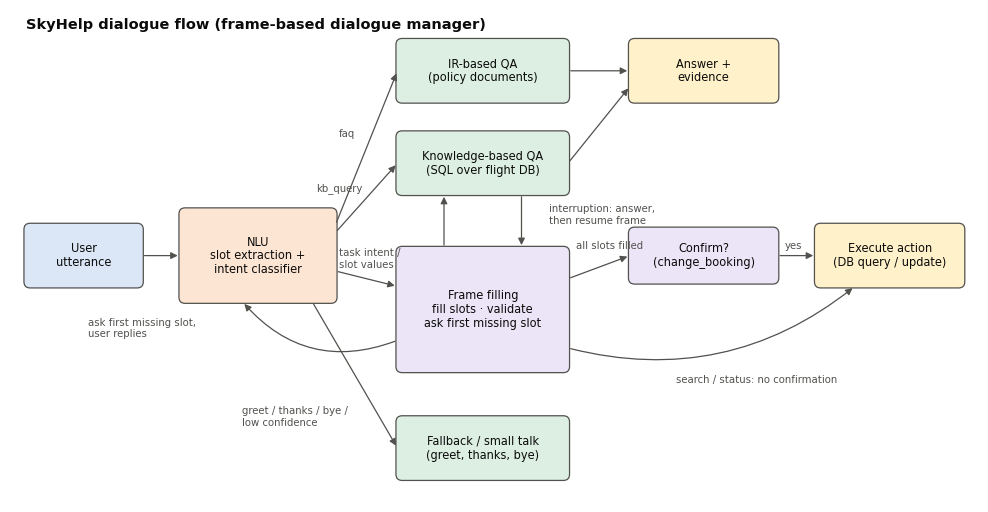

In [14]:
from matplotlib.patches import FancyBboxPatch
def draw_dialogue_flow(path=None):
    fig, ax = plt.subplots(figsize=(12.5, 6.4)); ax.set_xlim(0, 12.5); ax.set_ylim(0, 6.4); ax.axis("off")
    def box(x, y, w, h, text, fc):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec="#52514e", lw=0.9))
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=8.2, color="#0b0b0b")
        return (x, y, w, h)
    def arrow(p, q, label=None, rad=0.0, lx=0, ly=0):
        ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color="#52514e", lw=0.9, connectionstyle=f"arc3,rad={rad}"))
        if label:
            ax.text((p[0] + q[0]) / 2 + lx, (p[1] + q[1]) / 2 + ly, label, fontsize=7.3, color="#52514e", ha="center")
    U, N, Q, F, X = "#dbe7f6", "#fde5d3", "#dcefe2", "#ece5f7", "#fff1c9"
    box(0.2, 2.8, 1.5, 0.8, "User\nutterance", U)
    box(2.2, 2.6, 2.0, 1.2, "NLU\nslot extraction +\nintent classifier", N)
    box(5.0, 5.2, 2.2, 0.8, "IR-based QA\n(policy documents)", Q)
    box(5.0, 4.0, 2.2, 0.8, "Knowledge-based QA\n(SQL over flight DB)", Q)
    box(5.0, 0.3, 2.2, 0.8, "Fallback / small talk\n(greet, thanks, bye)", Q)
    box(5.0, 1.7, 2.2, 1.6, "Frame filling\nfill slots · validate\nask first missing slot", F)
    box(8.0, 2.85, 1.9, 0.7, "Confirm?\n(change_booking)", F)
    box(10.4, 2.8, 1.9, 0.8, "Execute action\n(DB query / update)", X)
    box(8.0, 5.2, 1.9, 0.8, "Answer +\nevidence", X)
    arrow((1.7, 3.2), (2.2, 3.2))
    arrow((4.2, 3.6), (5.0, 5.6), "faq", lx=-0.25, ly=0.15); arrow((4.2, 3.5), (5.0, 4.4), "kb_query", lx=-0.35, ly=0.1)
    arrow((4.2, 3.0), (5.0, 2.8)); ax.text(4.25, 3.05, "task intent /\nslot values", fontsize=7.3, color="#52514e")
    arrow((3.9, 2.6), (5.0, 0.7)); ax.text(3.0, 1.0, "greet / thanks / bye /\nlow confidence", fontsize=7.3, color="#52514e")
    arrow((7.2, 5.6), (8.0, 5.6)); arrow((7.2, 4.4), (8.0, 5.4))
    arrow((7.2, 2.9), (8.0, 3.2)); ax.text(7.3, 3.3, "all slots filled", fontsize=7.3, color="#52514e")
    arrow((9.9, 3.2), (10.4, 3.2)); ax.text(10.0, 3.3, "yes", fontsize=7.3, color="#52514e")
    arrow((7.2, 2.0), (10.9, 2.8), rad=0.25); ax.text(8.6, 1.55, "search / status: no confirmation", fontsize=7.3, color="#52514e")
    arrow((5.0, 2.1), (3.0, 2.6), rad=-0.35); ax.text(1.0, 2.15, "ask first missing slot,\nuser replies", fontsize=7.3, color="#52514e")
    arrow((5.6, 3.3), (5.6, 4.0)); arrow((6.6, 4.0), (6.6, 3.3))
    ax.text(6.95, 3.62, "interruption: answer,\nthen resume frame", fontsize=7.3, color="#52514e", ha="left")
    ax.text(0.2, 6.15, "SkyHelp dialogue flow (frame-based dialogue manager)", fontsize=10.5, weight="bold", color="#0b0b0b")
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    return fig
draw_dialogue_flow(OUT / "dialogue_flow.png"); plt.show()

In [15]:
def wd_name(iso):
    return date.fromisoformat(iso).strftime("%a %d %b")

class SkyHelp:
    """Frame-based help-desk chatbot combining IR-based QA, knowledge-based QA and task dialogues."""
    GREETING = "Hi, I'm SkyHelp from Skyline Regional Airways. Ask me about baggage, check-in, refunds or flights, or I can search flights, check a flight status or change a booking."

    def __init__(self, db=None):
        self.db = db or make_db()
        self.frame = None          # {"name", "slots", "requested", "confirming"}
        self.last_frame = None     # most recent frame (kept after completion for corrections)
        self.last_outcome = None
        self.trace = []

    # ---------- helpers
    def _new_frame(self, name):
        return {"name": name, "slots": {}, "requested": None, "confirming": False}

    def _fill(self, slots):
        """Copy the slots that belong to the active frame. Returns the names that were filled."""
        spec, filled = FRAMES[self.frame["name"]], []
        for k, v in slots.items():
            k = SLOT_OF.get(k, {}).get(self.frame["name"], k)
            if k in spec["required"] + spec["optional"]:
                self.frame["slots"][k] = v
                filled.append(k)
        if filled:
            self.frame["confirming"] = False
        return filled

    def _answer_question(self, text, intent):
        order = ["kb", "ir"] if intent == "kb_query" else ["ir", "kb"]
        for src in order:
            if src == "kb":
                r = kb_answer(text, self.db)
                if r["answer"]:
                    return r["answer"]
            else:
                r = qa_answer(text, tau=QA_TAU)
                if r["answer"]:
                    title = PASSAGES.set_index("pid").title[r["pid"]]
                    if r["answer_type"] == "OTHER":       # non-factoid question: quote the best evidence sentence
                        return f"Our policy says: \"{r['sentence']}\" (Source: {title})"
                    return f"{r['answer'].rstrip('.')}. (Source: {title} — \"{r['sentence']}\")"
        return ("Sorry, I couldn't find an answer to that in our policies or flight data. You can ask about baggage, "
                "check-in, refunds, flight times and fares, or I can search flights, check a flight status or change a booking.")

    # ---------- validation, prompting and actions
    def _validate(self):
        f, s = self.frame, self.frame["slots"]
        if f["name"] == "change_booking":
            if "pnr" in s:
                row = self.db.execute("SELECT flight_no, date, fare_class FROM bookings WHERE pnr=?", (s["pnr"],)).fetchone()
                if row is None:
                    bad = s.pop("pnr")
                    return f"I couldn't find a booking with reference {bad}. Please check it and try again."
                f["booking"] = row
            if "pnr" in s and "new_date" in s:
                flight, old, cls = f["booking"]
                days = self.db.execute("SELECT days FROM flights WHERE flight_no=?", (flight,)).fetchone()[0]
                wd = date.fromisoformat(s["new_date"]).strftime("%a")
                if days != "Daily" and wd not in days:
                    bad = s.pop("new_date")
                    return f"{flight} does not operate on {wd_name(bad)} (it flies {days}). Please choose another date."
                if s["new_date"] == old:
                    s.pop("new_date")
                    return f"Your booking is already on {wd_name(old)}. Which date would you like instead?"
        if f["name"] == "flight_status" and "flight_no" in s:
            if self.db.execute("SELECT 1 FROM flights WHERE flight_no=?", (s["flight_no"],)).fetchone() is None:
                bad = s.pop("flight_no")
                return f"I couldn't find flight {bad} in our schedule."
        if f["name"] == "search_flights" and s.get("origin") and s.get("origin") == s.get("destination"):
            s.pop("destination")
            return "The origin and destination are the same city."
        return None

    def _next_step(self, prefix=""):
        problem = self._validate()
        spec, s = FRAMES[self.frame["name"]], self.frame["slots"]
        missing = [k for k in spec["required"] if k not in s]
        if missing:
            self.frame["requested"] = missing[0]
            return " ".join(x for x in [prefix, problem, spec["prompts"][missing[0]]] if x)
        if spec["confirm"]:
            flight, old, cls = self.frame["booking"]
            fee = "a change fee of INR 2,999" if cls == "Saver" else "no change fee"
            self.frame["confirming"], self.frame["requested"] = True, None
            return (f"{prefix} I can move booking {s['pnr']} on {flight} from {wd_name(old)} to {wd_name(s['new_date'])}. "
                    f"Your {cls} fare has {fee}, plus any fare difference. Shall I go ahead?").strip()
        return " ".join(x for x in [prefix, self._execute()] if x)

    def _execute(self):
        name, s = self.frame["name"], self.frame["slots"]
        if name == "search_flights":
            wd = date.fromisoformat(s["date"]).strftime("%a")
            cls = s.get("fare_class", "Saver")
            rows = self.db.execute(
                "SELECT f.flight_no, f.dep_time, f.arr_time, f.aircraft, p.price FROM flights f JOIN fares p USING(flight_no) "
                "WHERE f.origin=? AND f.destination=? AND (f.days='Daily' OR f.days LIKE ?) AND p.fare_class=? ORDER BY f.dep_time",
                (s["origin"], s["destination"], f"%{wd}%", cls)).fetchall()
            route = f"{CITY_NAME[s['origin']]} to {CITY_NAME[s['destination']]} on {wd_name(s['date'])}"
            if rows:
                self.last_outcome = "results"
                reply = f"I found {len(rows)} flight{'s' if len(rows) > 1 else ''} from {route}: " + "; ".join(
                    f"{r[0]} {r[1]}→{r[2]} ({r[3]}), {cls} INR {r[4]:,}" for r in rows) + "."
            else:
                self.last_outcome = "no_flights"
                reply = f"Sorry, there are no Skyline flights from {route}."
        elif name == "flight_status":
            day = s.get("date", TODAY.isoformat())
            st = self.db.execute("SELECT status, gate, est_dep FROM flight_status WHERE flight_no=? AND date=?",
                                 (s["flight_no"], day)).fetchone()
            dep = self.db.execute("SELECT dep_time FROM flights WHERE flight_no=?", (s["flight_no"],)).fetchone()[0]
            self.last_outcome = "status"
            if st is None:
                reply = f"{s['flight_no']} on {wd_name(day)} is scheduled to depart on time at {dep}; no disruption has been reported."
            elif st[0] == "Cancelled":
                reply = f"{s['flight_no']} on {wd_name(day)} is Cancelled. You can rebook free of charge or ask for a full refund."
            elif st[0] == "Delayed":
                reply = f"{s['flight_no']} on {wd_name(day)} is Delayed: estimated departure {st[2]} (scheduled {dep}), gate {st[1]}."
            else:
                reply = f"{s['flight_no']} on {wd_name(day)}: {st[0]}, departure {st[2]}, gate {st[1]}."
        else:  # change_booking (after confirmation)
            self.db.execute("UPDATE bookings SET date=? WHERE pnr=?", (s["new_date"], s["pnr"]))
            self.last_outcome = "changed"
            reply = f"Done! Booking {s['pnr']} is now on {self.frame['booking'][0]} on {wd_name(s['new_date'])}. A confirmation e-mail is on its way."
        self.last_frame, self.frame = self.frame, None
        return reply

    # ---------- the policy
    def respond(self, text):
        intent, conf = classify(text)
        requested = self.frame["requested"] if self.frame else None
        slots = extract_slots(text, requested)
        reply, action = self._policy(text, intent, conf, slots)
        self.trace.append({"user": text, "intent": intent, "confidence": round(conf, 2), "slots": slots,
                           "action": action, "bot": reply})
        return reply

    def _policy(self, text, intent, conf, slots):
        f = self.frame
        if f:
            if f["confirming"]:
                yn = yes_no(text)
                if yn is True:
                    return self._execute(), "execute"
                if yn is False:
                    self.last_outcome, self.last_frame, self.frame = "not_changed", f, None
                    return "No problem, I have not changed your booking. Is there anything else I can help with?", "cancel"
            if self._fill(slots):
                return self._next_step(), "fill+next"
            if intent in ("faq", "kb_query") and conf >= OOS_THRESHOLD:
                return self._answer_question(text, intent) + " — Back to your request: " + self._next_step(), "interrupt-answer+resume"
            if intent in FRAMES and intent != f["name"] and conf >= OOS_THRESHOLD:
                self.frame = self._new_frame(intent); self._fill(slots)
                return self._next_step("Sure, let's do that instead."), "switch-frame"
            if intent == "goodbye":
                self.frame = None
                return "Goodbye, and thank you for flying Skyline!", "close"
            return "Sorry, I didn't catch that. " + self._next_step(), "reprompt"
        # no active frame
        if self.last_frame and slots and re.search(r"\b(meant|actually|instead|sorry|rather|make it|change it to)\b", text, re.I):
            self.frame = dict(self.last_frame, slots=dict(self.last_frame["slots"]), confirming=False)
            if self._fill(slots):
                return self._next_step("Updated."), "correction"
            self.frame = None
        if conf < OOS_THRESHOLD and not slots:
            return ("Sorry, I can only help with Skyline flights and travel policies. Try asking about baggage, "
                    "check-in or refunds, or say 'find a flight' or 'check my flight status'."), "fallback"
        if intent in FRAMES:
            self.frame = self._new_frame(intent); self._fill(slots)
            return self._next_step(), "open-frame"
        if intent in ("faq", "kb_query"):
            return self._answer_question(text, intent), "answer"
        if intent == "greet":
            return self.GREETING, "greet"
        if intent == "thanks":
            return "You're welcome! Anything else I can help with?", "thanks"
        return "Goodbye, and thank you for flying Skyline!", "close"

QA_TAU = 0.5   # abstention threshold, chosen on the development questions (see section 8)

## 7. Working prototype: demo conversations and interactive chat

Each demo below is run against a fresh copy of the database. Under every bot reply, the **NLU line** shows what the system understood (intent, confidence, slots) and which branch of the policy it took. This is useful for explaining the dialogue manager during a demo.

In [16]:
def run_dialogue(turns, show=True):
    bot = SkyHelp(make_db())
    for u in turns:
        r = bot.respond(u)
        if show:
            t = bot.trace[-1]
            print(f"USER : {u}\nBOT  : {r}\n       [intent={t['intent']} ({t['confidence']}), slots={t['slots']}, action={t['action']}]\n")
    return bot

print(SkyHelp.GREETING, "\n")
_ = run_dialogue(["Hi", "I want to fly to Mumbai", "When does the boarding gate close?", "from Bengaluru",
                  "next Monday", "What time does SR-205 arrive?", "thanks"])

Hi, I'm SkyHelp from Skyline Regional Airways. Ask me about baggage, check-in, refunds or flights, or I can search flights, check a flight status or change a booking. 

USER : Hi
BOT  : Hi, I'm SkyHelp from Skyline Regional Airways. Ask me about baggage, check-in, refunds or flights, or I can search flights, check a flight status or change a booking.
       [intent=greet (0.96), slots={}, action=greet]

USER : I want to fly to Mumbai
BOT  : Where will you be flying from?
       [intent=search_flights (0.93), slots={'destination': 'BOM'}, action=open-frame]

USER : When does the boarding gate close?
BOT  : 25 minutes. (Source: Check-in and boarding — "Boarding normally starts 50 minutes before departure and the boarding gate closes 25 minutes before departure.") — Back to your request: Where will you be flying from?
       [intent=faq (0.87), slots={}, action=interrupt-answer+resume]

USER : from Bengaluru
BOT  : What date would you like to travel?
       [intent=kb_query (0.62), slots=

In [17]:
_ = run_dialogue(["I need to change my booking", "K7Q2XZ", "move it to 25 October", "yes",
                  "Is SR-482 on time today?", "bye"])

USER : I need to change my booking
BOT  : Please tell me your 6-character booking reference (PNR).
       [intent=change_booking (0.97), slots={}, action=open-frame]

USER : K7Q2XZ
BOT  : Which date would you like to move it to?
       [intent=change_booking (0.62), slots={'pnr': 'K7Q2XZ'}, action=fill+next]

USER : move it to 25 October
BOT  : I can move booking K7Q2XZ on SR-482 from Sat 24 Oct to Sun 25 Oct. Your Saver fare has a change fee of INR 2,999, plus any fare difference. Shall I go ahead?
       [intent=change_booking (0.79), slots={'date': '2026-10-25'}, action=fill+next]

USER : yes
BOT  : Done! Booking K7Q2XZ is now on SR-482 on Sun 25 Oct. A confirmation e-mail is on its way.
       [intent=goodbye (0.3), slots={}, action=execute]

USER : Is SR-482 on time today?
BOT  : SR-482 on Tue 20 Oct is Delayed: estimated departure 15:15 (scheduled 14:30), gate 14.
       [intent=flight_status (0.92), slots={'flight_no': 'SR-482', 'date': '2026-10-20'}, action=open-frame]

USER : 

In [18]:
_ = run_dialogue(["Book a flight from Delhi to Goa", "Saturday", "sorry, I meant from Mumbai",
                  "Can I bring my cat in the cabin?", "What's the weather in Paris?"])

USER : Book a flight from Delhi to Goa
BOT  : What date would you like to travel?
       [intent=search_flights (0.95), slots={'origin': 'DEL', 'destination': 'GOX'}, action=open-frame]

USER : Saturday
BOT  : I found 1 flight from Delhi to Goa on Sat 24 Oct: SR-742 11:05→13:40 (Airbus A321), Saver INR 5,599.
       [intent=change_booking (0.6), slots={'date': '2026-10-24'}, action=fill+next]

USER : sorry, I meant from Mumbai
BOT  : Updated. Sorry, there are no Skyline flights from Mumbai to Goa on Sat 24 Oct.
       [intent=search_flights (0.48), slots={'origin': 'BOM'}, action=correction]

USER : Can I bring my cat in the cabin?
BOT  : Our policy says: "Pets are not allowed in the cabin." (Source: Pets and service animals)
       [intent=faq (0.78), slots={}, action=answer]

USER : What's the weather in Paris?
BOT  : Sorry, I couldn't find an answer to that in our policies or flight data. You can ask about baggage, check-in, refunds, flight times and fares, or I can search flights, 

In [19]:
def chat():
    """Interactive chat loop. Type 'quit' to stop."""
    bot = SkyHelp()
    print("SkyHelp:", SkyHelp.GREETING)
    while True:
        user = input("You: ").strip()
        if user.lower() in {"quit", "exit"}:
            print("SkyHelp: Goodbye!"); break
        print("SkyHelp:", bot.respond(user))

RUN_INTERACTIVE = False      # set to True to chat with the bot in this notebook
if RUN_INTERACTIVE:
    chat()

## 8. Evaluation

Each component is scored separately on the **held-out test sets**, with the development-set score shown alongside.

* **Retrieval:** Recall@k (is the gold passage among the top k?) and mean reciprocal rank.
* **Factoid QA:** exact match (EM) and token-level F1 after SQuAD-style normalisation, a lenient score (gold answer contained in the returned text) and abstention on unanswerable questions.
* **Knowledge-based QA:** answer accuracy (the right flights, or all required values present).
* **Intent classification:** accuracy and macro-F1, plus how many out-of-scope utterances are rejected.
* **Dialogue:** task success (correct final frame, slots, outcome and database state), slot accuracy and number of turns.

In [20]:
import os, string
SCORE_TEST = os.environ.get("LAB_DEV_ONLY") != "1"   # LAB_DEV_ONLY=1 scores only the dev sets while tuning

def norm_answer(s):
    s = s.lower().replace(",", "")
    s = "".join(ch for ch in s if ch not in set(string.punctuation) - {"@", "."})
    return " ".join(w for w in s.split() if w not in {"a", "an", "the"}).strip(" .")

def token_f1(pred, gold):
    p, g = norm_answer(pred).split(), norm_answer(gold).split()
    common = sum((Counter(p) & Counter(g)).values())
    if common == 0:
        return 0.0
    pr, rc = common / len(p), common / len(g)
    return 2 * pr * rc / (pr + rc)

def retrieval_metrics(qset, method):
    rows = [(retrieve(q, method, k=len(PASSAGES)), pid) for q, a, pid in qset if pid]
    ranks = [next(i for i, (p, _) in enumerate(hits, 1) if p == pid) for hits, pid in rows]
    return {"Recall@1": np.mean([r <= 1 for r in ranks]), "Recall@3": np.mean([r <= 3 for r in ranks]),
            "Recall@5": np.mean([r <= 5 for r in ranks]), "MRR": np.mean([1 / r for r in ranks])}

SPLITS = [("dev", FAQ_DEV)] + ([("test", FAQ_TEST)] if SCORE_TEST else [])
METHODS = {"tfidf": "TF-IDF (cosine)", "bm25": "BM25", "bm25+exp": "BM25 + query expansion"}
ret_rows = [{"split": sp, "retriever": METHODS[m], **{k: round(v, 3) for k, v in retrieval_metrics(qs, m).items()}}
            for sp, qs in SPLITS for m in METHODS]
RETRIEVAL = pd.DataFrame(ret_rows)
RETRIEVAL

,split,retriever,Recall@1,Recall@3,Recall@5,MRR
0,dev,TF-IDF (cosine),0.950,1.0,1.0,0.975
1,dev,BM25,0.900,1.0,1.0,0.942
2,dev,BM25 + query expansion,0.950,1.0,1.0,0.975
3,test,TF-IDF (cosine),0.833,1.0,1.0,0.910
4,test,BM25,0.917,1.0,1.0,0.958
5,test,BM25 + query expansion,0.917,1.0,1.0,0.958


In [21]:
def score_qa(qset, method="bm25+exp", extract=True, tau=QA_TAU):
    rows = []
    for q, gold, pid in qset:
        r = qa_answer(q, method=method, extract=extract, tau=tau)
        pred = r["answer"]
        if gold is None:
            rows.append({"question": q, "gold": "(unanswerable)", "prediction": pred or "(abstained)", "type": r["answer_type"],
                         "EM": float(pred is None), "F1": float(pred is None), "lenient": float(pred is None), "answerable": False})
        else:
            em = float(pred is not None and norm_answer(pred) == norm_answer(gold))
            f1 = token_f1(pred, gold) if pred else 0.0
            len_ok = float(pred is not None and norm_answer(gold) in norm_answer(pred))
            rows.append({"question": q, "gold": gold, "prediction": pred or "(abstained)", "type": r["answer_type"],
                         "EM": em, "F1": round(f1, 3), "lenient": len_ok, "answerable": True})
    return pd.DataFrame(rows)

def summarise_qa(df):
    a, u = df[df.answerable], df[~df.answerable]
    return {"EM (answerable)": round(a.EM.mean(), 3), "F1 (answerable)": round(a.F1.mean(), 3),
            "lenient (answerable)": round(a.lenient.mean(), 3),
            "false abstentions": int((a.prediction == "(abstained)").sum()),
            "unanswerable correctly refused": f"{int(u.EM.sum())}/{len(u)}",
            "overall accuracy (EM incl. refusals)": round(df.EM.mean(), 3)}

# abstention threshold: chosen on the development set only
tau_rows = []
for tau in [0.3, 0.4, 0.5, 0.6, 0.7]:
    d = score_qa(FAQ_DEV, tau=tau)
    tau_rows.append({"tau": tau, "dev overall accuracy": round(d.EM.mean(), 3),
                     "dev answerable EM": round(d[d.answerable].EM.mean(), 3),
                     "dev unanswerable refused": int(d[~d.answerable].EM.sum())})
display(pd.DataFrame(tau_rows))
print(f"QA_TAU = {QA_TAU} (highest dev accuracy; on ties the most permissive, so real questions are not refused)")

SYSTEMS = {"Full system: BM25 + expansion + typed extraction": dict(method="bm25+exp", extract=True),
           "Baseline A: TF-IDF retrieval + typed extraction": dict(method="tfidf", extract=True),
           "Baseline B: BM25 + expansion, best sentence only": dict(method="bm25+exp", extract=False)}
QA_RESULTS = {(sp, name): score_qa(qs, **cfg) for sp, qs in SPLITS for name, cfg in SYSTEMS.items()}
QA_SUMMARY = pd.DataFrame([{"split": sp, "system": name, **summarise_qa(df)} for (sp, name), df in QA_RESULTS.items()])
QA_SUMMARY

,tau,dev overall accuracy,dev answerable EM,dev unanswerable refused
0,0.3,0.955,1.00,1
1,0.4,0.955,1.00,1
2,0.5,0.955,1.00,1
3,0.6,0.909,0.95,1
4,0.7,0.864,0.85,2


QA_TAU = 0.5 (highest dev accuracy; on ties the most permissive, so real questions are not refused)


,split,system,EM (answerable),F1 (answerable),lenient (answerable),false abstentions,unanswerable correctly refused,overall accuracy (EM incl. refusals)
0,dev,Full system: BM25 + expansion + typed extraction,1.000,1.000,1.000,0,1/2,0.955
1,dev,Baseline A: TF-IDF retrieval + typed extraction,1.000,1.000,1.000,0,2/2,1.000
2,dev,"Baseline B: BM25 + expansion, best sentence only",0.000,0.184,0.900,0,1/2,0.045
3,test,Full system: BM25 + expansion + typed extraction,0.792,0.812,0.792,3,4/4,0.821
4,test,Baseline A: TF-IDF retrieval + typed extraction,0.792,0.812,0.792,3,4/4,0.821
5,test,"Baseline B: BM25 + expansion, best sentence only",0.000,0.195,0.833,2,4/4,0.143


### Sample question–answer set (held-out test, full system)
This is the sample Q-A deliverable: every test question with its gold answer, the system's answer and whether it was correct.

In [22]:
if SCORE_TEST:
    sample_qa = QA_RESULTS[("test", list(SYSTEMS)[0])][["question", "type", "gold", "prediction", "EM", "F1"]]
    sample_qa.to_csv(OUT / "sample_qa_test.csv", index=False)
    display(sample_qa)

,question,type,gold,prediction,EM,F1
0,How many kilos of checked luggage do Flex tickets allow?,COUNT(kilos),20 kg,(abstained),0.0,0.0
1,What is the largest combined size allowed for a checked bag?,DIMENSION,158 cm,(abstained),0.0,0.0
2,How much do I pay per kg if I pre-book extra baggage online?,MONEY,INR 450,INR 450,1.0,1.0
3,How heavy can my personal item be?,WEIGHT,3 kg,10 kg,0.0,0.5
4,What are the maximum dimensions of a cabin bag?,DIMENSION,55 x 35 x 25 cm,55 x 35 x 25 cm,1.0,1.0
5,How much cabin baggage can Business passengers carry?,WEIGHT,10 kg,10 kg,1.0,1.0
6,Up to what capacity can a power bank be carried without approval?,QUANTITY,100 Wh,100 Wh,1.0,1.0
7,How long before the flight does online check-in close?,DURATION,60 minutes,60 minutes,1.0,1.0
8,At what point does boarding usually begin?,DURATION,50 minutes,50 minutes,1.0,1.0
9,How much does it cost to cancel a Business ticket two days before the flight?,MONEY,free of charge,"INR 3,500",0.0,0.0


In [23]:
def kb_correct(ans, gold):
    if not ans:
        return False
    if "flights" in gold:
        return set(re.findall(r"SR-\d{3}", ans)) == set(gold["flights"])
    return all(g in ans for g in gold["contains"])

KB_SPLITS = [("dev", KB_DEV)] + ([("test", KB_TEST)] if SCORE_TEST else [])
kb_rows = []
for sp, qs in KB_SPLITS:
    for q, gold in qs:
        r = kb_answer(q)
        kb_rows.append({"split": sp, "question": q, "relation": r["relation"], "SQL": r["sql"],
                        "answer": r["answer"], "correct": kb_correct(r["answer"], gold)})
KB_RESULTS = pd.DataFrame(kb_rows)
KB_RESULTS.to_csv(OUT / "kbqa_results.csv", index=False)
display(KB_RESULTS.groupby("split").correct.agg(["sum", "count", "mean"]).round(3))
KB_RESULTS[KB_RESULTS.split == ("test" if SCORE_TEST else "dev")][["question", "relation", "answer", "correct"]]

,sum,count,mean
split,,,
dev,12,12,1.0
test,14,14,1.0


,question,relation,answer,correct
12,At what time does flight SR 205 take off?,dep_time,SR-205 departs Bengaluru at 07:20.,True
13,What time does SR-916 land?,arr_time,SR-916 arrives in Kolkata at 23:00.,True
14,What type of plane flies SR-633?,aircraft,SR-633 is operated by an Airbus A320neo.,True
15,Show me flights from Bangalore to Kolkata,route_flights,Flights from Bengaluru to Kolkata: SR-916 20:15→23:00 (Daily).,True
16,How long does it take to fly from Mumbai to Kolkata?,duration,The flight takes 2 h 45 min.,True
17,What's the lowest price from Delhi to Goa?,cheapest,"The cheapest Saver fare from Delhi to Goa is INR 5,599 on SR-742.",True
18,How much is a Business class ticket on SR-482?,flight_fare,"A Business fare on SR-482 costs INR 19,799.",True
19,Which terminal at Mumbai airport does Skyline use?,terminal,At Mumbai (Chhatrapati Shivaji Maharaj International Airport) Skyline uses T2.,True
20,What is the name of the airport in Chennai?,airport_name,Skyline flies to Chennai International Airport in Chennai.,True
21,Which city has the airport code COK?,code_to_city,COK is Cochin International Airport in Kochi.,True


,classifier,accuracy,macro-F1
0,Logistic regression (word + char TF-IDF),0.975,0.975
1,Multinomial Naive Bayes (word TF-IDF),0.938,0.938


{'out-of-scope rejected': '2/6', 'in-domain test wrongly rejected': '0/80', 'out-of-scope refused end-to-end': '5/6'}


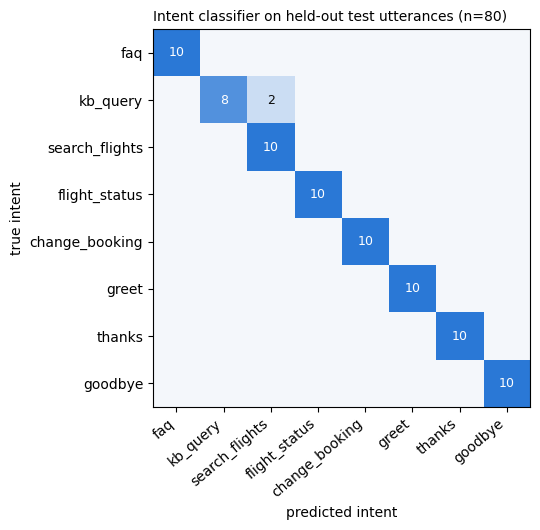

,utterance,true,predicted
0,Flights from Bangalore to Kolkata?,kb_query,search_flights
1,Lowest fare from Delhi to Goa?,kb_query,search_flights


In [24]:
if SCORE_TEST:
    pred_lr, pred_nb = intent_clf.predict(X_test), nb_clf.predict(X_test)
    INTENT_SUMMARY = pd.DataFrame([
        {"classifier": "Logistic regression (word + char TF-IDF)", "accuracy": round(accuracy_score(y_test, pred_lr), 3),
         "macro-F1": round(f1_score(y_test, pred_lr, average="macro"), 3)},
        {"classifier": "Multinomial Naive Bayes (word TF-IDF)", "accuracy": round(accuracy_score(y_test, pred_nb), 3),
         "macro-F1": round(f1_score(y_test, pred_nb, average="macro"), 3)}])
    display(INTENT_SUMMARY)
    oos_conf = [classify(u)[1] for u in OUT_OF_SCOPE]
    in_conf = [classify(u)[1] for u, _ in INTENT_TEST]
    OOS = {"out-of-scope rejected": f"{sum(c < OOS_THRESHOLD for c in oos_conf)}/{len(OUT_OF_SCOPE)}",
           "in-domain test wrongly rejected": f"{sum(c < OOS_THRESHOLD for c in in_conf)}/{len(in_conf)}"}
    # end-to-end: does the whole bot refuse? (the IR/KB stages can still decline after the classifier lets it through)
    e2e = [SkyHelp(make_db()).respond(u) for u in OUT_OF_SCOPE]
    OOS["out-of-scope refused end-to-end"] = f"{sum(r.startswith('Sorry') for r in e2e)}/{len(OUT_OF_SCOPE)}"
    print(OOS)
    labels = list(INTENT_TRAIN)
    cm = confusion_matrix(y_test, pred_lr, labels=labels)
    fig, ax = plt.subplots(figsize=(6.4, 5.4))
    from matplotlib.colors import LinearSegmentedColormap
    ax.imshow(cm, cmap=LinearSegmentedColormap.from_list("seq", ["#f4f7fb", "#2a78d6"]))
    ax.set_xticks(range(len(labels)), labels, rotation=40, ha="right"); ax.set_yticks(range(len(labels)), labels)
    for i in range(len(labels)):
        for j in range(len(labels)):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9, color="#ffffff" if cm[i, j] > 5 else "#0b0b0b")
    ax.set_xlabel("predicted intent"); ax.set_ylabel("true intent")
    ax.set_title("Intent classifier on held-out test utterances (n=80)", loc="left", fontsize=10)
    fig.tight_layout(); fig.savefig(OUT / "intent_confusion.png", dpi=200); plt.show()
    wrong = [(u, t, p) for (u, t), p in zip(INTENT_TEST, pred_lr) if t != p]
    display(pd.DataFrame(wrong, columns=["utterance", "true", "predicted"]))

In [25]:
def evaluate_dialogue(d):
    bot = run_dialogue(d["turns"], show=False)
    exp = d["expect"]
    fr = bot.frame or bot.last_frame
    slots = fr["slots"] if fr else {}
    slot_hits = sum(slots.get(k) == v for k, v in exp["slots"].items())
    replies = " ".join(t["bot"] for t in bot.trace)
    checks = {"frame": bool(fr) and fr["name"] == exp["frame"],
              "slots": slot_hits == len(exp["slots"]),
              "outcome": bot.last_outcome == exp["outcome"],
              "reply content": all(c in replies for c in exp.get("contains", [])),
              "database": all(bot.db.execute("SELECT date FROM bookings WHERE pnr=?", (p,)).fetchone()[0] == v
                              for p, v in exp.get("db", {}).items())}
    return {"dialogue": d["name"], "turns": len(d["turns"]), "slot accuracy": f"{slot_hits}/{len(exp['slots'])}",
            "success": all(checks.values()), "failed checks": ", ".join(k for k, v in checks.items() if not v) or "-"}, bot

DLG_SPLITS = [("dev", DIALOGUES_DEV)] + ([("test", DIALOGUES_TEST)] if SCORE_TEST else [])
dlg_rows, DLG_BOTS = [], {}
for sp, ds in DLG_SPLITS:
    for d in ds:
        row, bot = evaluate_dialogue(d)
        dlg_rows.append({"split": sp, **row}); DLG_BOTS[(sp, d["name"])] = bot
DIALOGUE_RESULTS = pd.DataFrame(dlg_rows)
display(DIALOGUE_RESULTS)
DIALOGUE_RESULTS.groupby("split").agg(success_rate=("success", "mean"), dialogues=("success", "size"),
                                      avg_turns=("turns", "mean")).round(3)

,split,dialogue,turns,slot accuracy,success,failed checks
0,dev,basic search,5,3/3,True,-
1,dev,status in one turn,1,1/1,True,-
2,dev,change booking,4,2/2,True,-
3,dev,over-informative user,1,3/3,True,-
4,dev,FAQ interruption,4,3/3,True,-
5,test,"greeting, alias, relative date",5,3/3,True,-
6,test,status - cancelled flight,1,1/1,True,-
7,test,"reschedule, Flex fare",4,2/2,True,-
8,test,user corrects origin,3,3/3,True,-
9,test,status - slot request,2,1/1,True,-


,success_rate,dialogues,avg_turns
split,,,
dev,1.0,5,3.0
test,1.0,8,3.0


## 9. Evaluation summary

In [26]:
if SCORE_TEST:
    full = list(SYSTEMS)[0]
    t_qa = summarise_qa(QA_RESULTS[("test", full)])
    t_ret = RETRIEVAL[(RETRIEVAL.split == "test") & (RETRIEVAL.retriever == "BM25 + query expansion")].iloc[0]
    t_kb = KB_RESULTS[KB_RESULTS.split == "test"].correct
    t_dlg = DIALOGUE_RESULTS[DIALOGUE_RESULTS.split == "test"]
    SUMMARY = pd.DataFrame([
        {"component": "Passage retrieval (BM25 + expansion)", "held-out test result": f"Recall@1 {t_ret['Recall@1']:.3f}, Recall@3 {t_ret['Recall@3']:.3f}, MRR {t_ret['MRR']:.3f}"},
        {"component": "IR-based factoid QA", "held-out test result": f"EM {t_qa['EM (answerable)']:.3f}, F1 {t_qa['F1 (answerable)']:.3f} on answerable; {t_qa['unanswerable correctly refused']} unanswerable refused"},
        {"component": "Knowledge-based QA (SQL)", "held-out test result": f"{int(t_kb.sum())}/{len(t_kb)} correct ({t_kb.mean():.3f})"},
        {"component": "Intent classification", "held-out test result": f"accuracy {INTENT_SUMMARY.accuracy[0]:.3f}, macro-F1 {INTENT_SUMMARY['macro-F1'][0]:.3f}; out-of-scope {OOS['out-of-scope refused end-to-end']} refused end-to-end"},
        {"component": "Task dialogues", "held-out test result": f"{int(t_dlg.success.sum())}/{len(t_dlg)} successful, {t_dlg.turns.mean():.1f} user turns on average"},
    ])
    SUMMARY.to_csv(OUT / "evaluation_summary.csv", index=False)
    json.dump({"qa_test": {k: (v if isinstance(v, str) else float(v)) for k, v in t_qa.items()},
               "retrieval": RETRIEVAL.to_dict("records"), "qa_summary": QA_SUMMARY.to_dict("records"),
               "kb": KB_RESULTS.groupby("split").correct.agg(["sum", "count"]).reset_index().to_dict("records"),
               "intent": INTENT_SUMMARY.to_dict("records"), "oos": OOS, "oos_threshold": OOS_THRESHOLD,
               "dialogues": DIALOGUE_RESULTS.to_dict("records")},
              open(OUT / "metrics.json", "w"), indent=1, default=str)
    display(SUMMARY)

,component,held-out test result
0,Passage retrieval (BM25 + expansion),"Recall@1 0.917, Recall@3 1.000, MRR 0.958"
1,IR-based factoid QA,"EM 0.792, F1 0.812 on answerable; 4/4 unanswerable refused"
2,Knowledge-based QA (SQL),14/14 correct (1.000)
3,Intent classification,"accuracy 0.975, macro-F1 0.975; out-of-scope 5/6 refused end-to-end"
4,Task dialogues,"8/8 successful, 3.0 user turns on average"


### Findings

* **The structured parts generalise well.** Knowledge-based QA answered all 14 test questions and all 8 test dialogues succeeded, including aliases (*Bangalore*, *Madras*), a different flight-number spelling (*SR 205*), corrections, a change to a day the flight does not operate, a refused confirmation and an interruption mid-task. The gazetteer is built from the database and the dialogue policy is generic, so new phrasings mostly reuse the same paths. All of these tests were written by the same author as the system, so real users will be more varied.
* **Factoid QA dropped from 1.00 exact match on the development questions to 0.79 on the test questions.** This is the clearest sign of rules fitted to the development phrasing. The five failures are instructive:
  1. *"How many **kilos** …"*: spaCy lemmatises *kilos* as *kilos*, not *kilo*, so the question was typed `COUNT(kilos)` instead of `WEIGHT`, and with no candidate the system refused.
  2. *"largest combined size"*: the paraphrase shares few words with *"sum of its length, width and height"*. Coverage was 0.44, just under the 0.5 threshold, so it refused.
  3. *"minimum number of miles"*: no answer-type rule covers *"number of"*, so the type was `OTHER` and coverage 0.45 led to a refusal.
  4. *"How heavy can my personal item be?"*: the Business-class sentence also mentions *personal item* and ranked first, giving **10 kg** instead of **3 kg**.
  5. *"cost to cancel a Business ticket two days before"*: the answer, *free of charge*, is not a money amount and needs reasoning about the 24-hour rule, so the system answered **INR 3,500**.
* **Abstention works in the safe direction.** All 4 unanswerable test questions were refused, at the cost of 3 answerable ones also being refused. A lower threshold would answer more but guess more often.
* **BM25 beats TF-IDF at rank 1 on the test questions** (Recall@1 0.917 vs 0.833). Query expansion did not change test ranking, and Recall@3 is 1.0 for every retriever. Because the extractor reads the top 3 passages, the TF-IDF pipeline ties the full system end-to-end. A 35-passage corpus is too small to separate the retrievers clearly.
* **Intent classification:** logistic regression beats Naive Bayes (0.975 vs 0.938). Both errors are terse questions (*"Flights from Bangalore to Kolkata?"*) that read like booking requests, which is genuinely ambiguous. On its own, the confidence threshold rejected only 2 of 6 out-of-scope messages. The QA stages then declined to answer three more, so 5 of 6 were refused end-to-end. *"Play some music"* got a greeting.